# Project Chefs' Recipes Classification

- Laura Scherzberg
- Pedro Machado
- Vasco Brito

This project concerns the research question of whether classical machine learning algorithms can successfully compete with more complex methods (such as Transformer-based models) in correctly classifying chefs' recipes. This is a simple text classification problem.

Throughout the notebook, the training dataset is explored, assessed, processed and modelled through conventional Natural Language Processing methodologies. Several of these are explored and their effictiveness is taken into account.

Then, the construction and training of the machine learning models is conducted. The results of these are compared, in particular, with a more modern and complex method.

Finally, using the best model, predictions on the test set are retrieved and saved.

In [ ]:
# Utilities
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json
import ast
from scipy import stats
from joblib import Parallel, delayed

# NLP
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download("wordnet")

# Training utilities
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModel
import torch

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

pd.options.mode.chained_assignment = None

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


First and foremost, let us look at our data, its size, and its features. Features containing lists of strings will be read as such instead of simple strings.

In [ ]:
data = pd.read_csv('train.csv', delimiter=';')

for col in ['tags', 'steps', 'ingredients']:
    data[col] = data[col].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else [])

print(data.shape)
data

(2999, 8)


,chef_id,recipe_name,data,tags,steps,description,ingredients,n_ingredients
0,5060,chefy s rice pudding,29/01/2002,"[60-minutes-or-less, time-to-make, course, mai...","[cook rice according to package directions, sc...","by request, from georgian bay gourmet.","[long grain rice, half-and-half cream, eggs, s...",6
1,3288,lasagna in the pressure cooker,14/12/2016,"[30-minutes-or-less, time-to-make, course, mai...","[in the opened pressure cooker , add the oil a...",i love how quickly i can put together a meal i...,"[olive oil, onion, ground beef, pasta sauce, w...",13
2,5060,ham frittata,22/09/2004,"[60-minutes-or-less, time-to-make, course, mai...","[heat oven to 400f, heat oil in a non stick fr...",great for a quick meal with left over ham! lot...,"[olive oil, cooked ham, onion, red sweet bell ...",12
3,1533,red pepper garlic sauce,12/04/2005,"[15-minutes-or-less, time-to-make, course, mai...",[in a small mixing bowl mix all above ingredie...,this was so nice on salmon and we also have tr...,"[red peppers, garlic cloves, mayonnaise, salt ...",4
4,5060,simple easy stuffed roast chicken with gravy ...,14/10/2004,"[time-to-make, course, main-ingredient, cuisin...","[preheat oven to 400f, empty contents of stuff...",this method can be used for roast chicken or t...,"[chicken flavor stuffing mix, hot water, butte...",13
...,...,...,...,...,...,...,...,...
2994,8688,cheesy potato skins,22/01/2007,"[60-minutes-or-less, time-to-make, course, mai...","[preheat oven to 400f, scrub the potatoes, wit...",love potato skins but don't need all the fat a...,"[russet potatoes, olive oil, paprika, salt, ca...",6
2995,4470,bbq lamb with canadian whisky,10/03/2002,"[weeknight, time-to-make, main-ingredient, cui...","[in a bowl stir together the soy , whiskey and...",not only is canadian rye (whiskey) good as a d...,"[leg of lamb, brown sugar, canadian rye whisky...",4
2996,8688,coffee buttercream frosting,12/03/2007,"[60-minutes-or-less, time-to-make, course, pre...","[beat cream , sugar , hot coffee , egg yolks a...",i discovered this recipe in lee lee's recipe b...,"[whipping cream, sugar, strong coffee, egg yol...",8
2997,5060,coriander dippin sauce,26/02/2002,"[15-minutes-or-less, time-to-make, course, cui...","[in a small bowl combine yogurt , coriander an...",good for dippin anything but best with recipe ...,"[low-fat plain yogurt, fresh coriander leaves,...",3


We have 2999 rows and 8 columns.

Naturally, "chef_id" is the target feature. In addition, there are 5 textual features containing, respectively, the recipe's name, summary tags, cooking steps, description, and ingredients. Tags, steps, and ingredients are contained in a list.

There is also a date feature, "data", and a numeric one, "n_ingredients". The former seems to contain the date the recipe was either written, published, etc. This is not clear. The latter seems to contain the number of ingredients in the recipe.

It is pertinent to assess whether any features contain null or incoherent values.

In [ ]:
data.describe(include='all')

,chef_id,recipe_name,data,tags,steps,description,ingredients,n_ingredients
count,2999.000000,2999,2999,2999,2999,2999,2999,2999.000000
unique,NaN,2985,1045,2976,2979,2959,2985,NaN
top,NaN,grilled sweetcorn,28/03/2002,"[15-minutes-or-less, time-to-make, course, pre...","[combine ingredients in a 12 oz cup, mix well]",yum,"[corn on the cob, butter, salt, pepper]",NaN
freq,NaN,4,41,5,6,11,4,NaN
mean,4843.314438,NaN,NaN,NaN,NaN,NaN,NaN,9.072357
std,2073.810822,NaN,NaN,NaN,NaN,NaN,NaN,3.686936
min,1533.000000,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
25%,3288.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000
50%,4470.000000,NaN,NaN,NaN,NaN,NaN,NaN,9.000000
75%,6357.000000,NaN,NaN,NaN,NaN,NaN,NaN,11.000000


In [ ]:
data.dtypes

,0
chef_id,int64
recipe_name,object
data,object
tags,object
steps,object
description,object
ingredients,object
n_ingredients,int64


It seems no feature contains null values. However, from the output above, one may note that "chef_id" is of a numeric data type. It is relevant to turn it into a purely categorical feature.

Additionally, "data" is of the "object" data type, a string. This is not very intuitive and it could be of the "datetime" data type. Nonetheless, it will be kept as it is.

In [ ]:
data['chef_id'] = data['chef_id'].astype('category')

Now, let us investigate possible incoherent values. Firstly, we simply look at "chef_id"'s values. Since it is the target feature, we'll look at its distribution.

[]

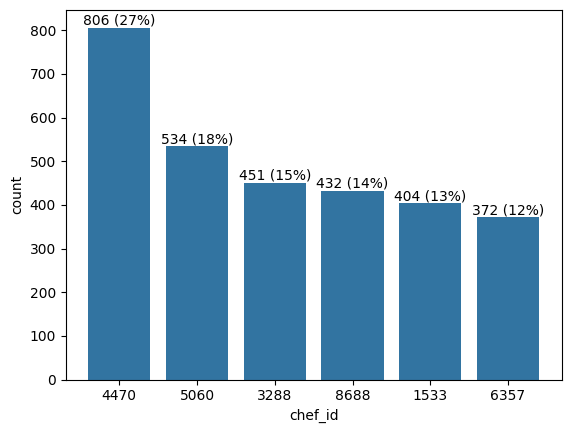

In [ ]:
abs_values = data['chef_id'].value_counts(ascending=False)
rel_values = data['chef_id'].value_counts(ascending=False, normalize=True)*100

count_labels = [f'{pair[0]} ({pair[1]:.0f}%)' for pair in zip(abs_values, rel_values)]

ax = sns.countplot(x=data['chef_id'], order=abs_values.index)
ax.bar_label(container=ax.containers[0], labels=count_labels)
plt.plot()

The values seem adequate. We have six distinct chefs. However, their recipes are not in equal proportions. In other words, our dataset has some imbalance. This will affect our modelling efforts, as models will tend to attribute more importance to the more prevalent chef: chef 4470.

Now, we can look into "data", our date feature. Because it should represent dates, we can parse them as such to assess whether we have unexpected and incoherent values. These can be very early or late dates, values which cannot be parsed into dates, or any other inconsistency.

In [ ]:
dates = pd.to_datetime(data['data'], dayfirst=True)
dates

,data
0,2002-01-29
1,2016-12-14
2,2004-09-22
3,2005-04-12
4,2004-10-14
...,...
2994,2007-01-22
2995,2002-03-10
2996,2007-03-12
2997,2002-02-26


All values could be parsed into the correct date format, which indicates the values should be correct. Do they make sense?

In [ ]:
print(dates.min())
print(dates.max())

dif_date = [date for date in data['data'] if len(date) != 10]
print(dif_date)

1999-08-06 00:00:00
2016-12-14 00:00:00
[]


All dates seem correct. The minimum and maximum dates are reasonable and there are no dates, prior to formatting, that are not in the correct format nor correspond to an unexpected string.

Now, let us jump to the "n_ingredients" feature. We can plot its probability distribution, both in general and per chef. This will help us assess whether values make sense.

[]

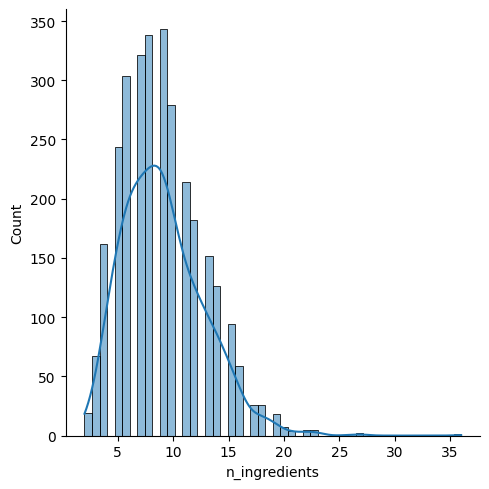

In [ ]:
sns.displot(data['n_ingredients'], kde=True)
plt.plot()

[]

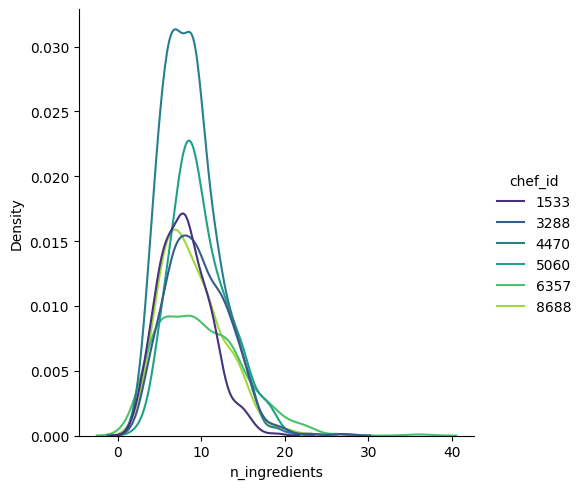

In [ ]:
sns.displot(data, x='n_ingredients', kind='kde', hue='chef_id', palette='viridis')
plt.plot()

Interestingly, there seem to be quite a few recipes with one ingredient only. Parallely, there seems to be a couple with over 36 ingredients. However, no absolutely absurd values exist.

Additionally, the distributions per chef do not seem to be too different.

When it comes to the textual features, analyzing all their values together is a daunting task, one which seems to be unfruitful. However, it is pertinent to plot the most common tags and ingredients, both altogether and per chef. The latter may help us in the future while trying to understand the instances that our model may label incorrectly.

We can do the same for both the steps and description, but we'll assess individual words, rather than the entire elements of the list (in the case of "steps").

Top 15 Tags:
preparation           2997
time-to-make          2983
course                2846
main-ingredient       2715
dietary               2711
equipment             2272
occasion              2197
cuisine               1872
easy                  1576
vegetables            1352
north-american        1351
low-in-something      1305
dinner-party          1240
number-of-servings    1035
stove-top             1013
Name: count, dtype: int64



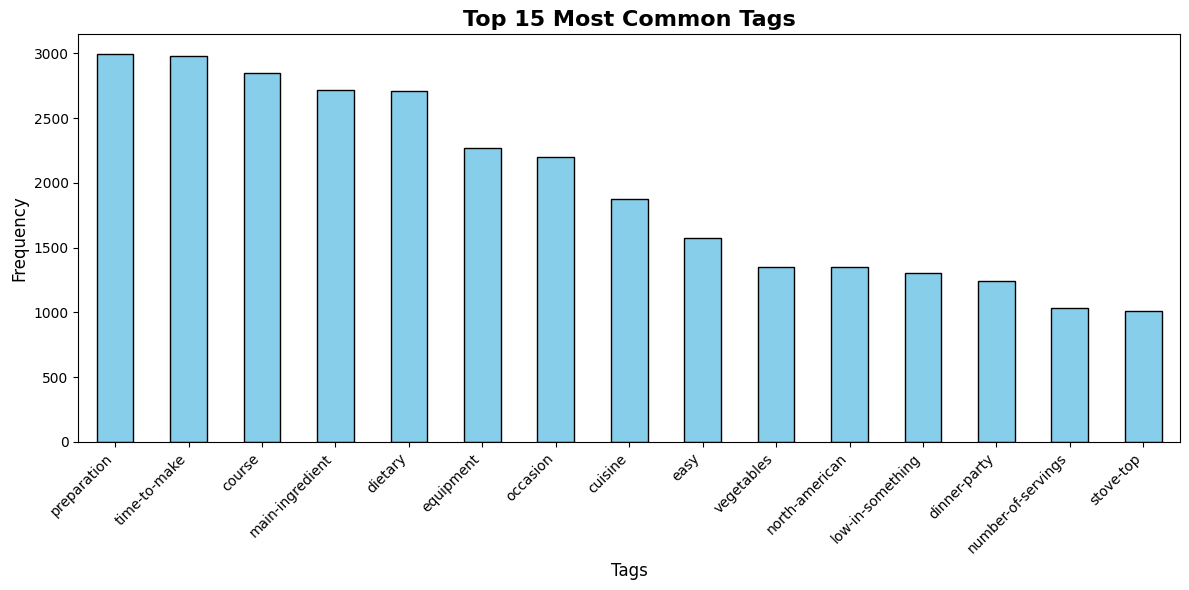

Top 15 Ingredients:
salt               1136
butter              574
garlic              564
onion               527
water               461
sugar               451
olive oil           389
pepper              312
eggs                305
tomatoes            257
salt and pepper     242
garlic cloves       241
milk                234
parmesan cheese     223
onions              216
Name: count, dtype: int64



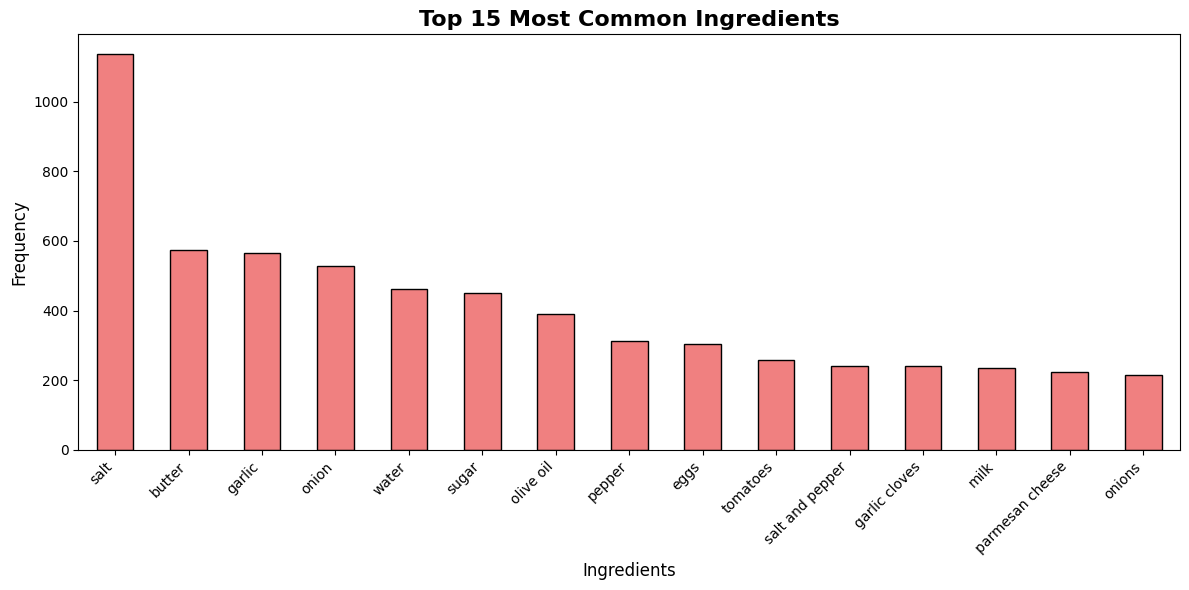

In [ ]:
# Tags analysis with bar graph
flat_tags = pd.Series([tag for tag_list in data['tags'] for tag in tag_list])
tags_counts = flat_tags.value_counts().head(15)

print("Top 15 Tags:")
print(tags_counts)
print()

# Create bar graph for tags
plt.figure(figsize=(12, 6))
tags_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 15 Most Common Tags', fontsize=16, fontweight='bold')
plt.xlabel('Tags', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Ingredients analysis with bar graph
flat_ingredients = pd.Series([ingredient for ingredient_list in data['ingredients'] for ingredient in ingredient_list])
ingredients_counts = flat_ingredients.value_counts().head(15)

print("Top 15 Ingredients:")
print(ingredients_counts)
print()

# Create bar graph for ingredients
plt.figure(figsize=(12, 6))
ingredients_counts.plot(kind='bar', color='lightcoral', edgecolor='black')
plt.title('Top 15 Most Common Ingredients', fontsize=16, fontweight='bold')
plt.xlabel('Ingredients', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


These words are a good indication, but they would be more relevant if segregated per chef. For this analysis, given the different magnitudes in the number of recipes per chef, we should look at normalized counts.

Top 10 Tags per Chef:
     chef_id                tags  count  total_tags_per_chef  normalized_count
196     1533         preparation    404                 9061          0.044587
260     1533        time-to-make    401                 9061          0.044256
71      1533              course    398                 9061          0.043925
79      1533             dietary    385                 9061          0.042490
151     1533     main-ingredient    367                 9061          0.040503
89      1533           equipment    341                 9061          0.037634
270     1533          vegetables    211                 9061          0.023287
145     1533    low-in-something    200                 9061          0.022073
84      1533                easy    189                 9061          0.020859
168     1533            occasion    178                 9061          0.019645
484     3288         preparation    451                11710          0.038514
555     3288        time-to-ma

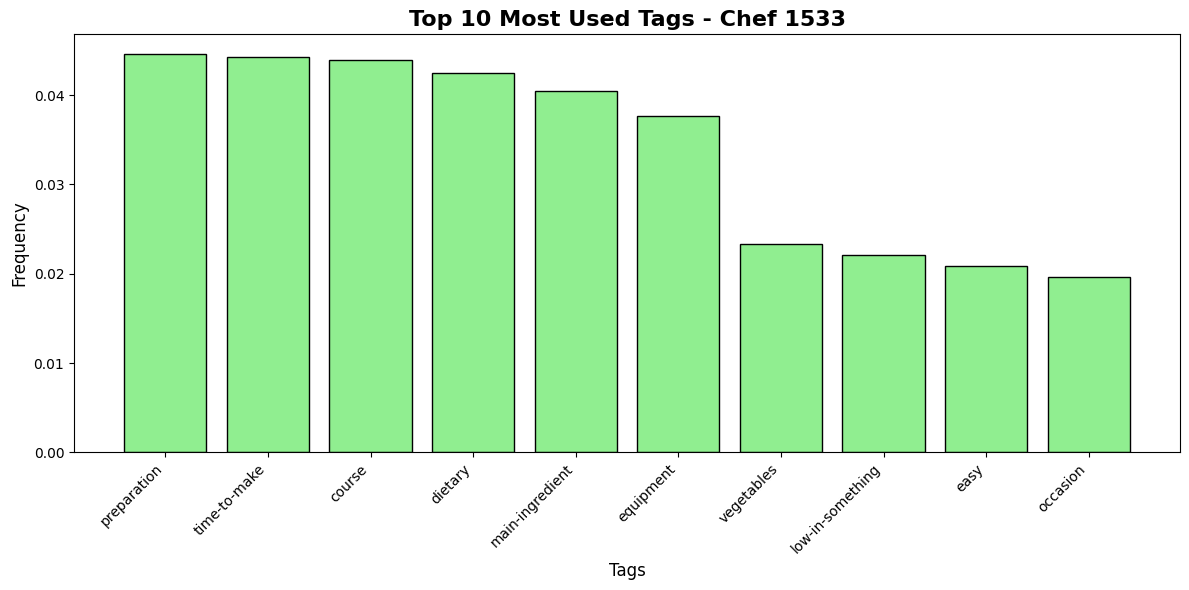

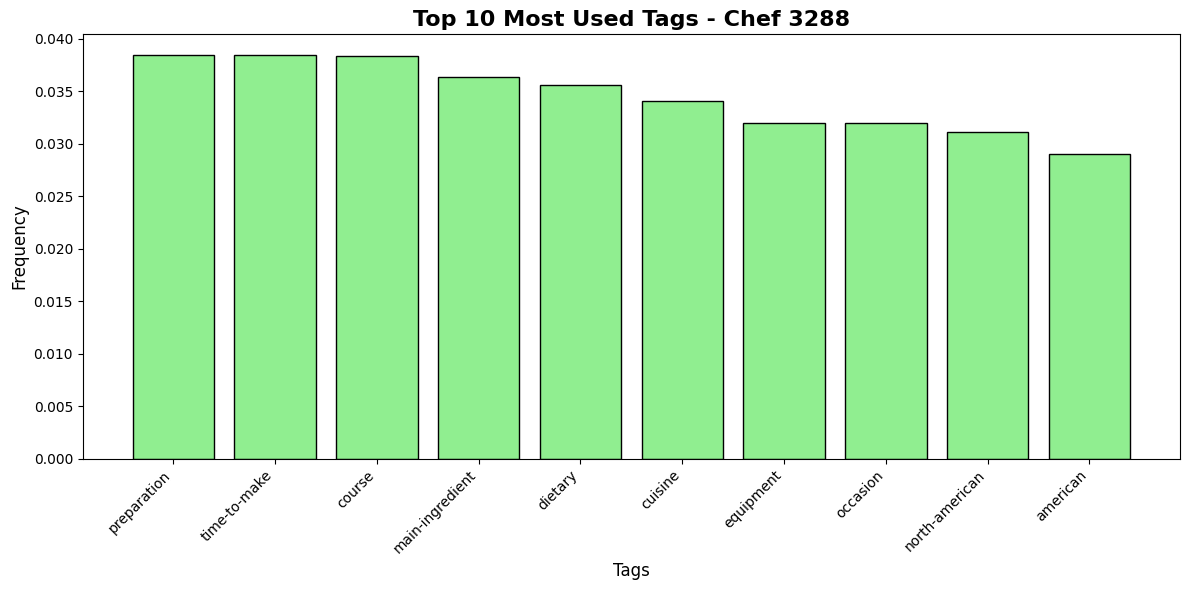

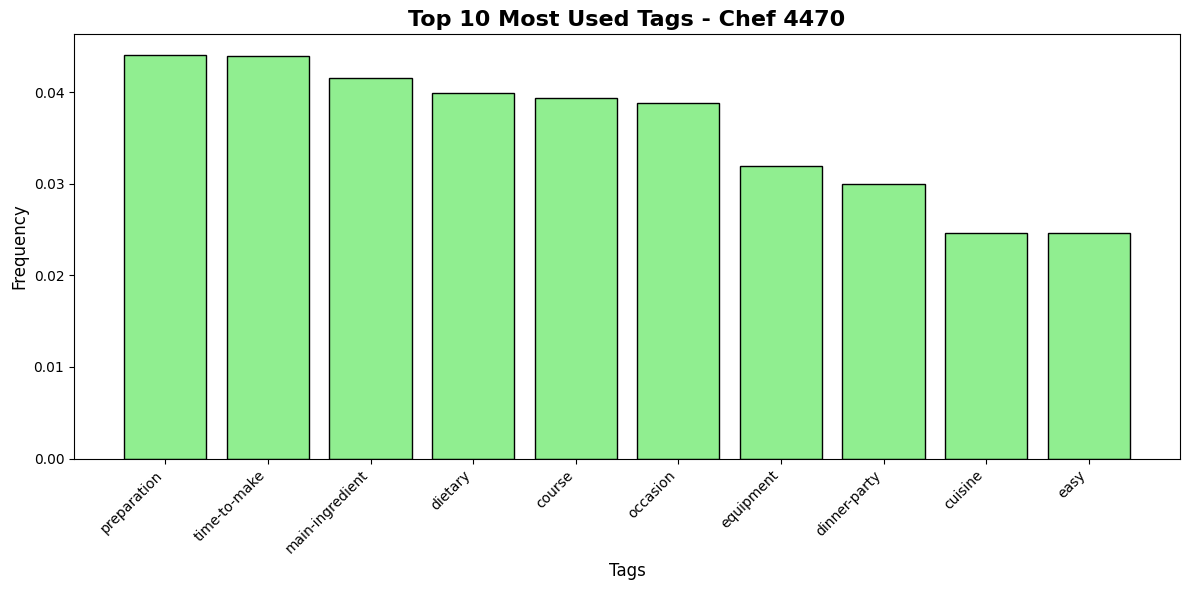

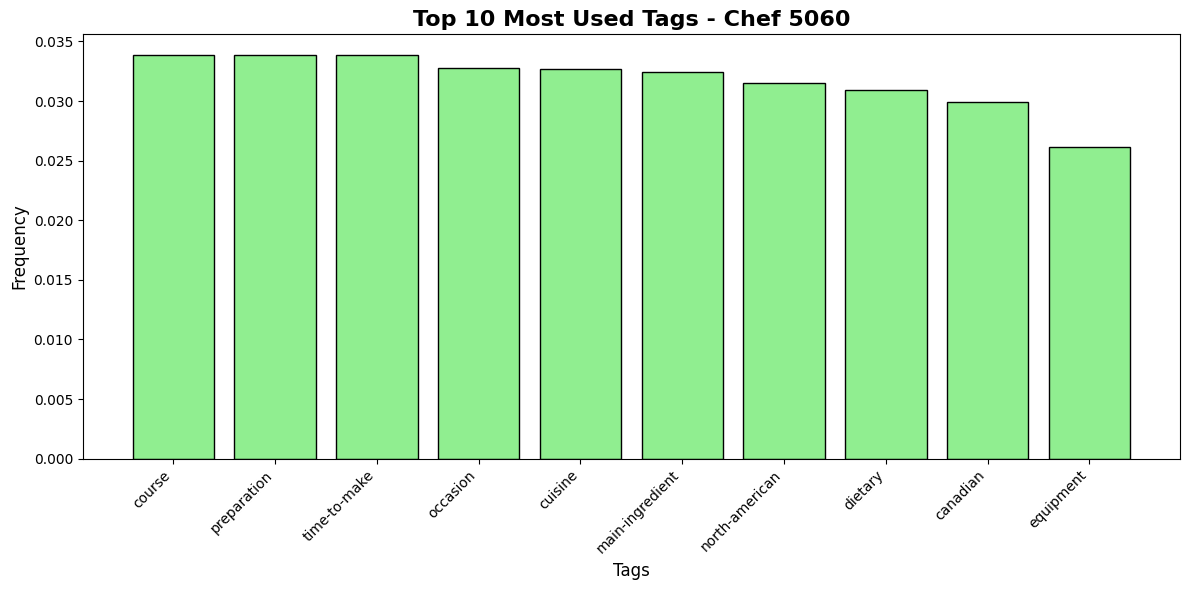

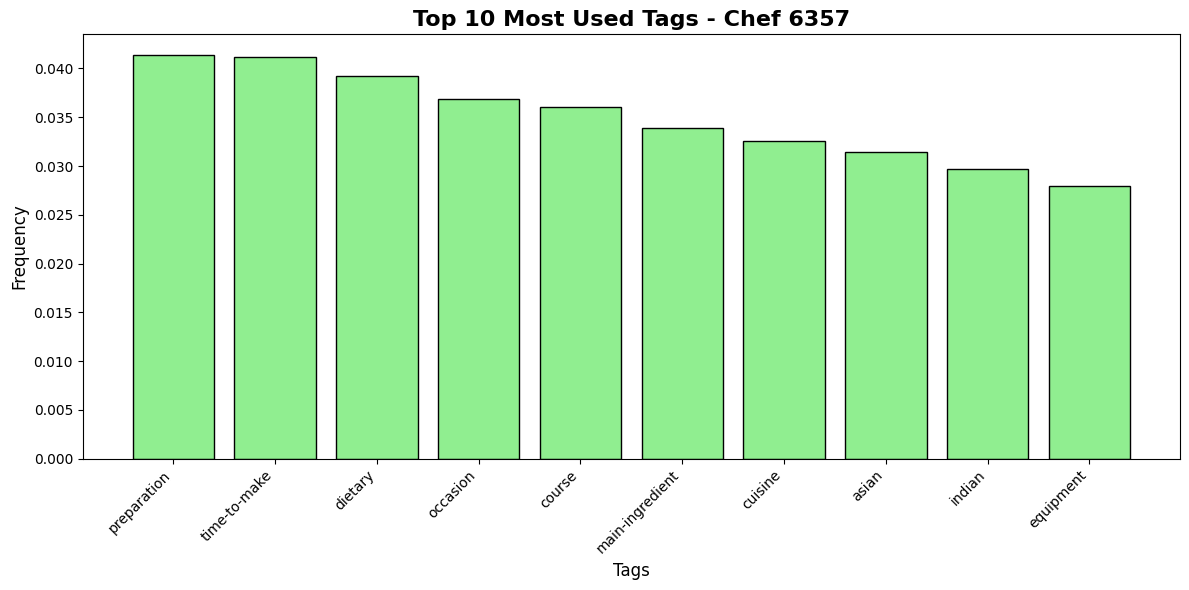

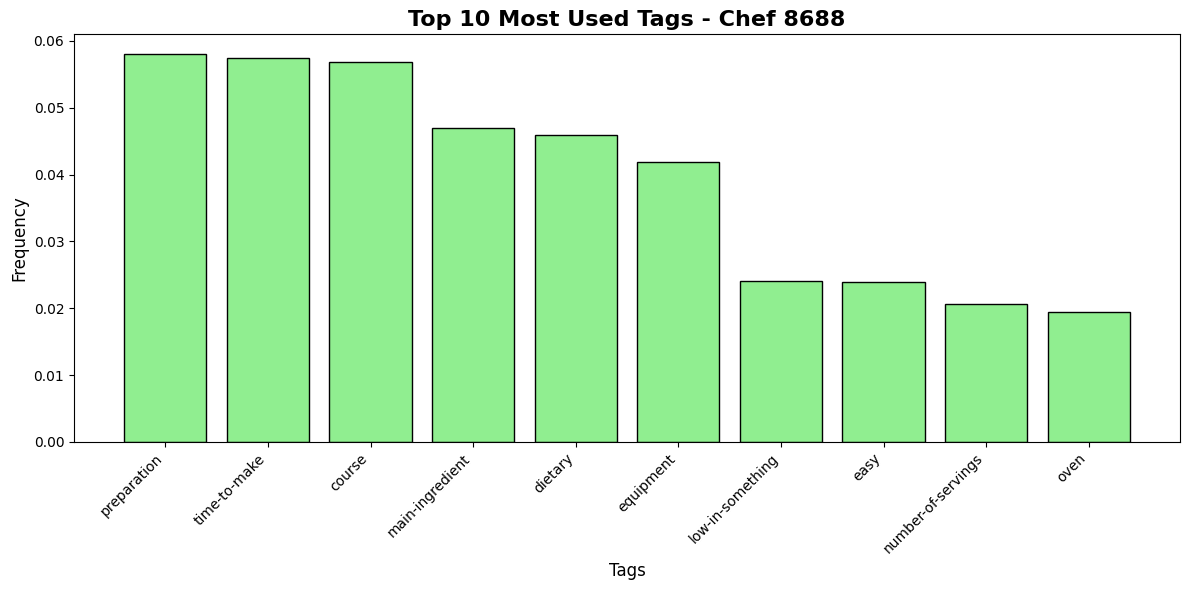

Top 10 Ingredients per Chef:
     chef_id        ingredients  count  total_ingredients_per_chef  \
793     1533               salt    116                        3252   
392     1533             garlic     81                        3252   
634     1533              onion     74                        3252   
632     1533          olive oil     72                        3252   
858     1533              sugar     55                        3252   
99      1533             butter     53                        3252   
942     1533              water     44                        3252   
670     1533             pepper     42                        3252   
517     1533        lemon juice     37                        3252   
909     1533           tomatoes     30                        3252   
1956    3288               salt    182                        4303   
1483    3288             garlic    115                        4303   
1765    3288              onion     89                       

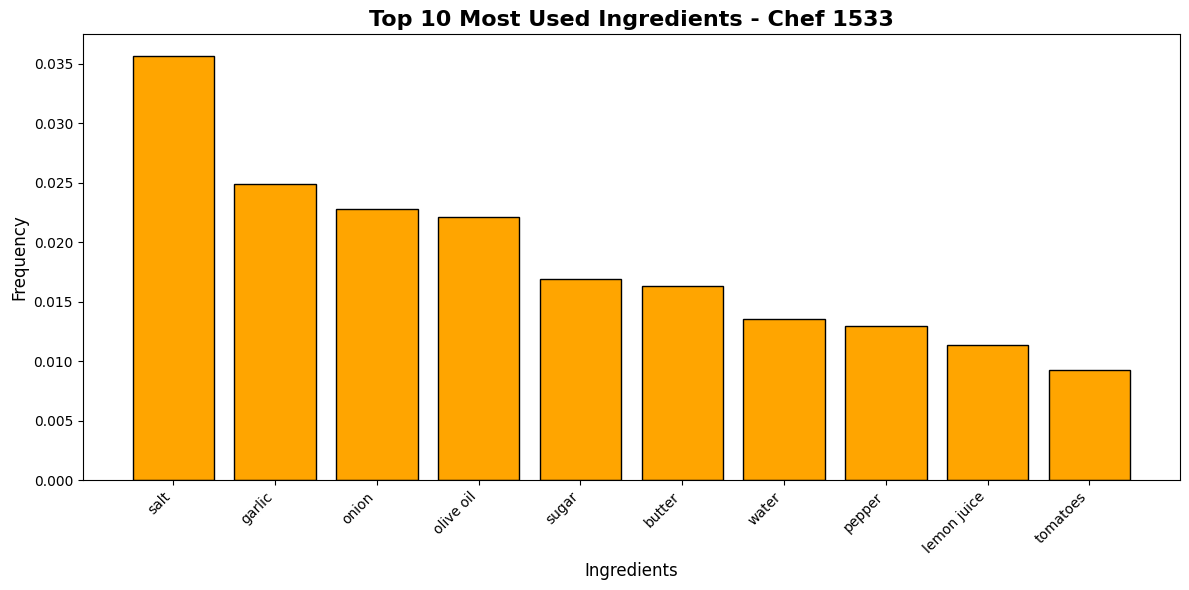

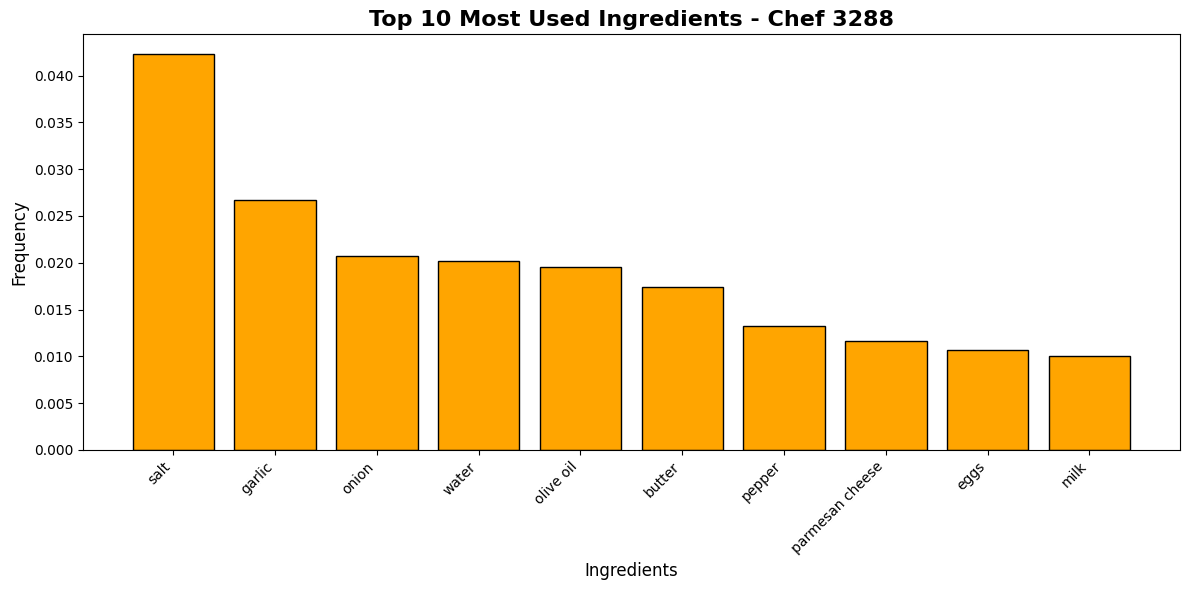

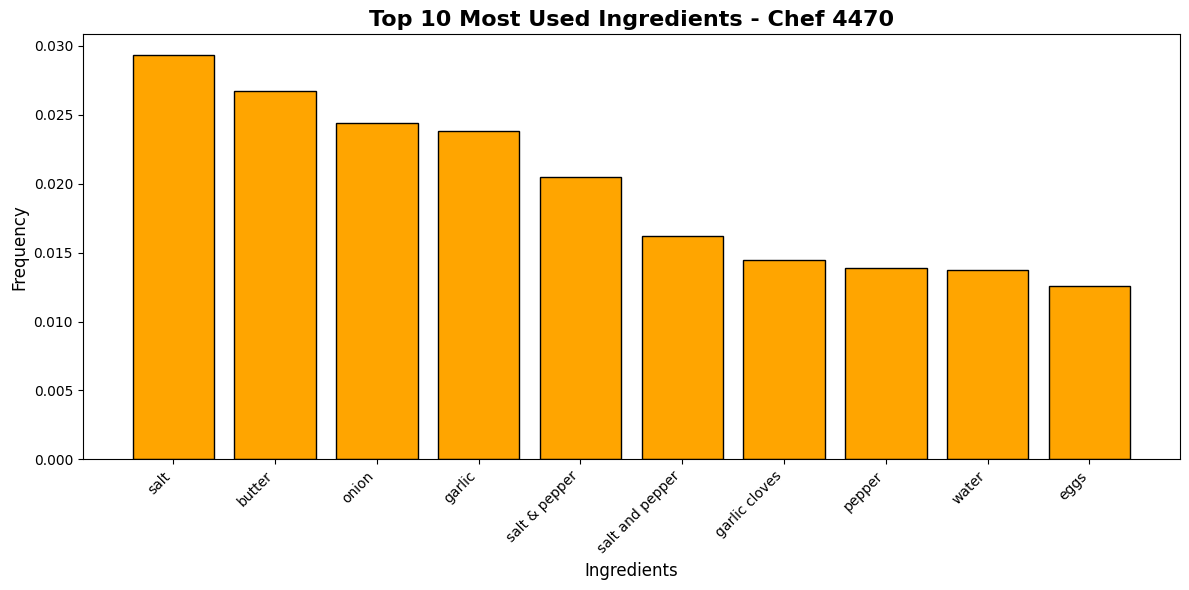

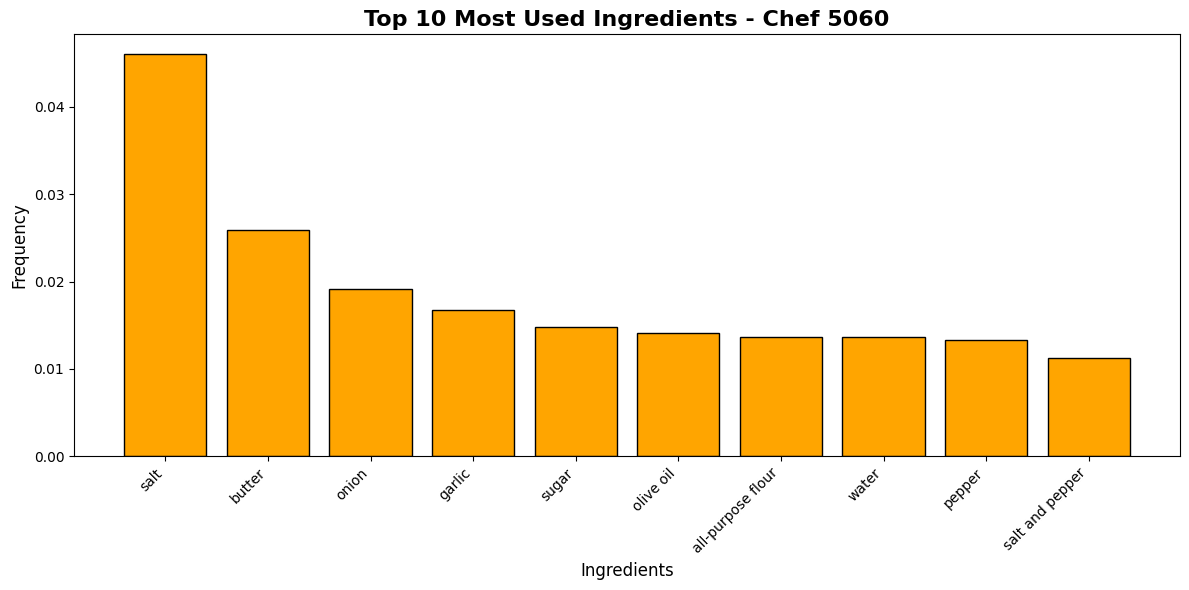

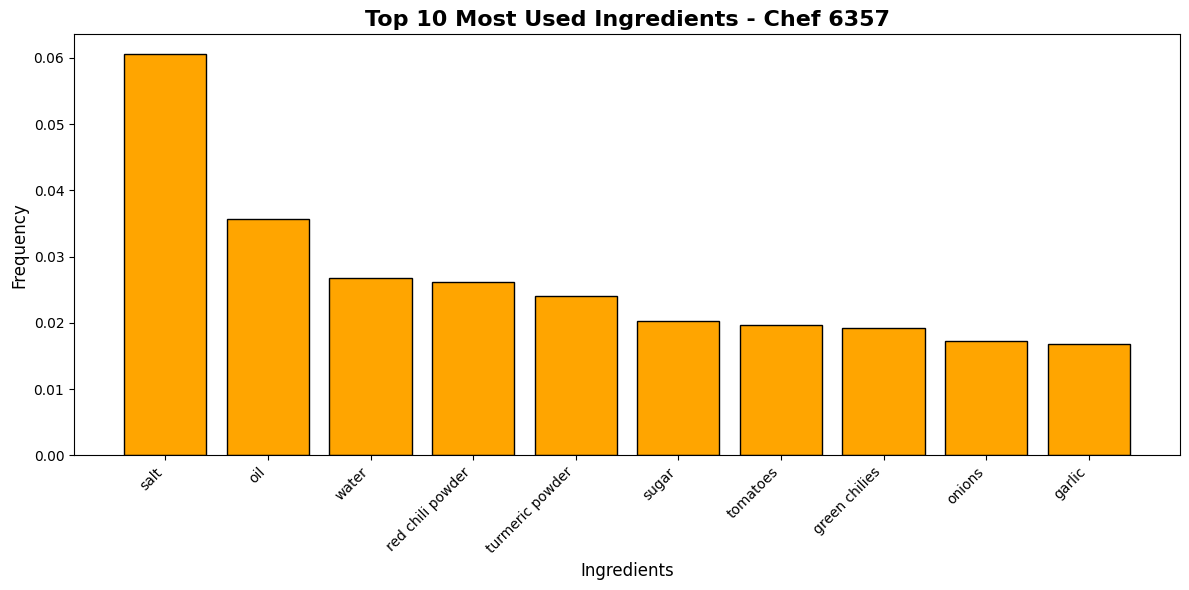

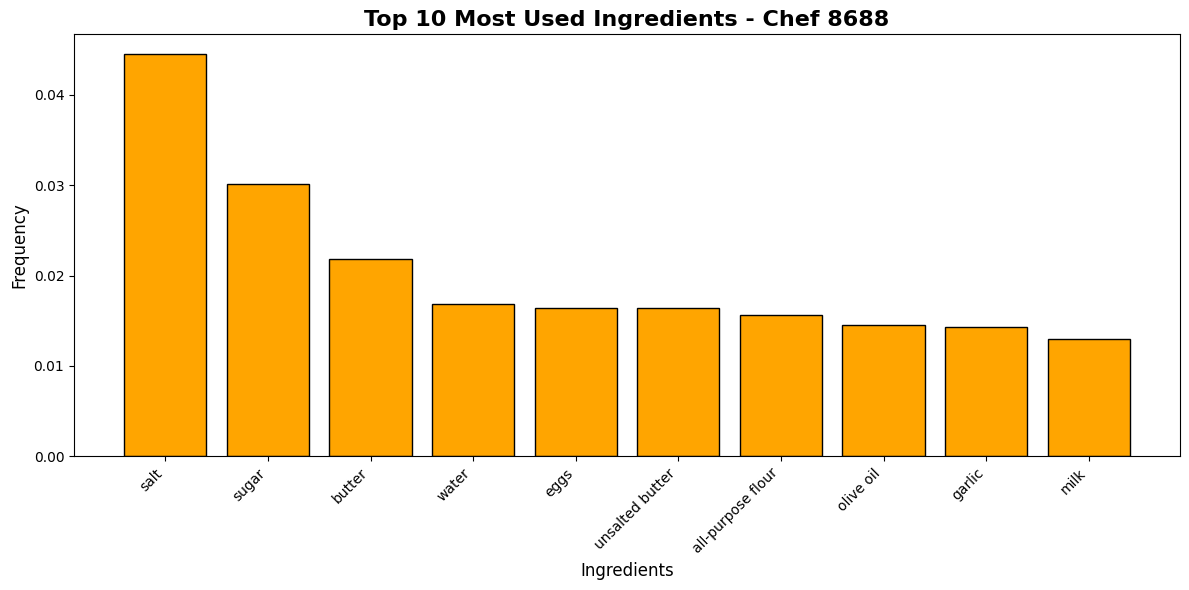

In [ ]:
# Chef tags analysis
chef_tag_counts = data[['chef_id', 'tags']].explode('tags').groupby(['chef_id', 'tags'], observed=True).size().reset_index(name='count')
chef_tag_full_count = data[['chef_id', 'tags']].explode('tags').groupby(['chef_id'], observed=True).size().reset_index(name='total_tags_per_chef')

chef_tag_counts = chef_tag_counts.merge(chef_tag_full_count, on='chef_id', how='left')
chef_tag_counts['normalized_count'] = chef_tag_counts['count']/chef_tag_counts['total_tags_per_chef']
top_chef_tags = chef_tag_counts.sort_values(["chef_id", "normalized_count"], ascending=[True, False]).groupby('chef_id', observed=True).head(10)

print("Top 10 Tags per Chef:")
print(top_chef_tags)
print()

# Create bar graphs for top tags per chef
unique_chefs = top_chef_tags['chef_id'].unique()

for chef_id in unique_chefs:
    chef_data = top_chef_tags[top_chef_tags['chef_id'] == chef_id]

    plt.figure(figsize=(12, 6))
    plt.bar(chef_data['tags'], chef_data['normalized_count'], color='lightgreen', edgecolor='black')
    plt.title(f'Top 10 Most Used Tags - Chef {chef_id}', fontsize=16, fontweight='bold')
    plt.xlabel('Tags', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Chef ingredients analysis
chef_ingredient_counts = data[['chef_id', 'ingredients']].explode('ingredients').groupby(['chef_id', 'ingredients'], observed=True).size().reset_index(name='count')
chef_ingredient_full_count = data[['chef_id', 'ingredients']].explode('ingredients').groupby(['chef_id'], observed=True).size().reset_index(name='total_ingredients_per_chef')

chef_ingredient_counts = chef_ingredient_counts.merge(chef_ingredient_full_count, on='chef_id', how='left')
chef_ingredient_counts['normalized_count'] = chef_ingredient_counts['count']/chef_ingredient_counts['total_ingredients_per_chef']
top_chef_ingredients = chef_ingredient_counts.sort_values(["chef_id", "normalized_count"], ascending=[True, False]).groupby('chef_id', observed=True).head(10)

print("Top 10 Ingredients per Chef:")
print(top_chef_ingredients)
print()

# Create bar graphs for top ingredients per chef
for chef_id in unique_chefs:
    chef_data = top_chef_ingredients[top_chef_ingredients['chef_id'] == chef_id]

    plt.figure(figsize=(12, 6))
    plt.bar(chef_data['ingredients'], chef_data['normalized_count'], color='orange', edgecolor='black')
    plt.title(f'Top 10 Most Used Ingredients - Chef {chef_id}', fontsize=16, fontweight='bold')
    plt.xlabel('Ingredients', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

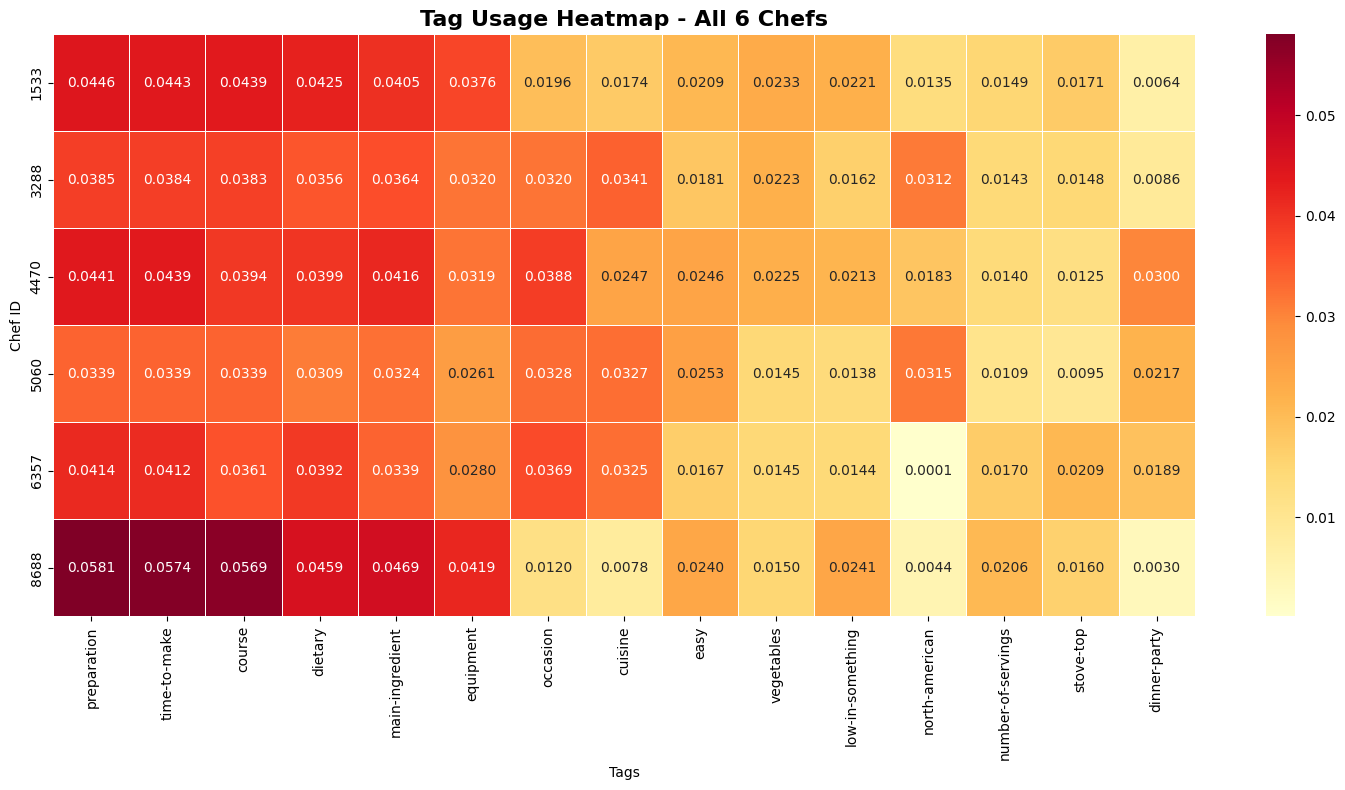

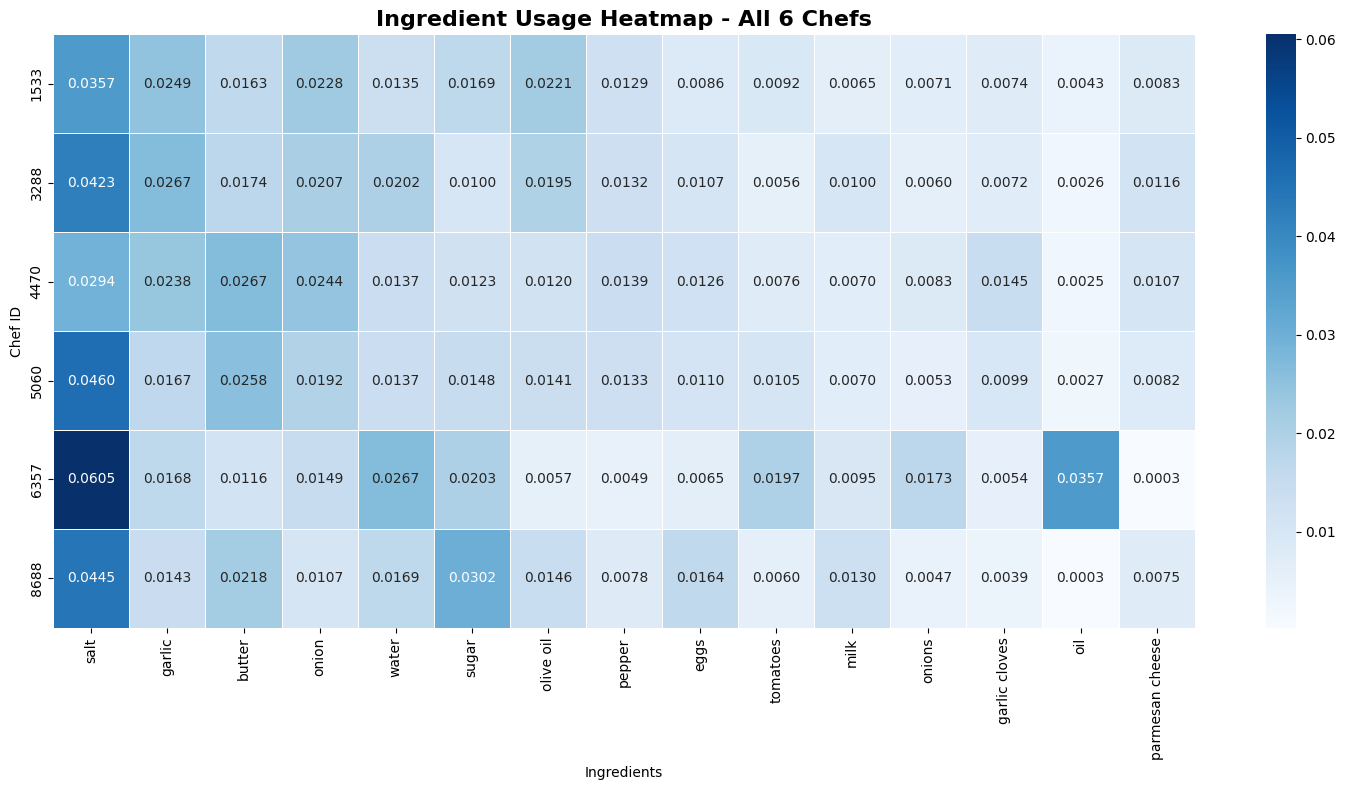

In [ ]:
# Prepare data for heatmap - Tags
chef_tag_pivot = chef_tag_counts.pivot_table(
    index='chef_id',
    columns='tags',
    values='normalized_count',
    fill_value=0,
    observed=True
)

# Take top N most common tags across all chefs for cleaner visualization
top_tags_across_chefs = chef_tag_pivot.mean().nlargest(15).index
chef_tag_pivot = chef_tag_pivot[top_tags_across_chefs]

plt.figure(figsize=(15, 8))
sns.heatmap(chef_tag_pivot, annot=True, cmap='YlOrRd', fmt='.4f', linewidths=0.5)
plt.title('Tag Usage Heatmap - All 6 Chefs', fontsize=16, fontweight='bold')
plt.xlabel('Tags')
plt.ylabel('Chef ID')
plt.tight_layout()
plt.show()

# Heatmap for Ingredients
chef_ingredient_pivot = chef_ingredient_counts.pivot_table(
    index='chef_id',
    columns='ingredients',
    values='normalized_count',
    fill_value=0,
    observed=True
)

top_ingredients_across_chefs = chef_ingredient_pivot.mean().nlargest(15).index
chef_ingredient_pivot = chef_ingredient_pivot[top_ingredients_across_chefs]

plt.figure(figsize=(15, 8))
sns.heatmap(chef_ingredient_pivot, annot=True, cmap='Blues', fmt='.4f', linewidths=0.5)
plt.title('Ingredient Usage Heatmap - All 6 Chefs', fontsize=16, fontweight='bold')
plt.xlabel('Ingredients')
plt.ylabel('Chef ID')
plt.tight_layout()
plt.show()

We can see that chefs have both tags and ingredients quite in common, generally. It seems that by themselves these elements may serve little help.

Let us now repeat the assessment with words in "steps" and "description".

Top 15 Most Common Words in Steps:
the        14156
and        13256
in          7654
a           7002
to          6559
with        4950
until       4236
add         4015
minutes     3908
of          3439
for         3409
heat        2714
or          2701
on          2487
over        2218
Name: count, dtype: int64



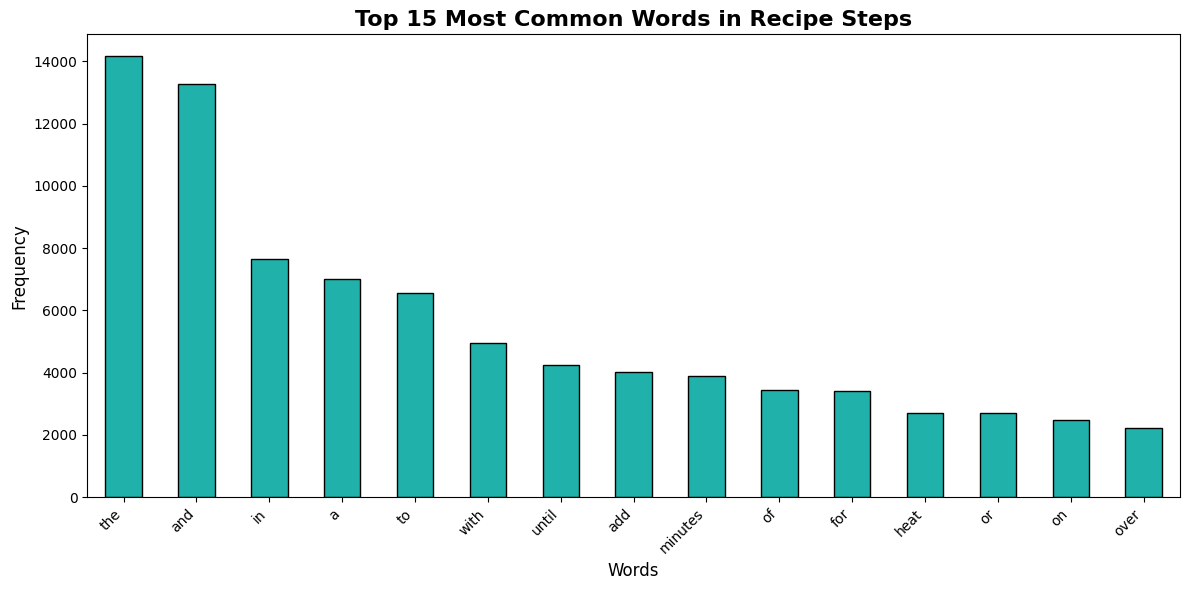

Top 15 Most Common Words in Descriptions:
the       3187
a         2794
this      2387
and       2184
to        1893
is        1701
i         1591
you       1400
it        1392
of        1362
for       1317
in        1181
with      1163
recipe     862
or         850
Name: count, dtype: int64



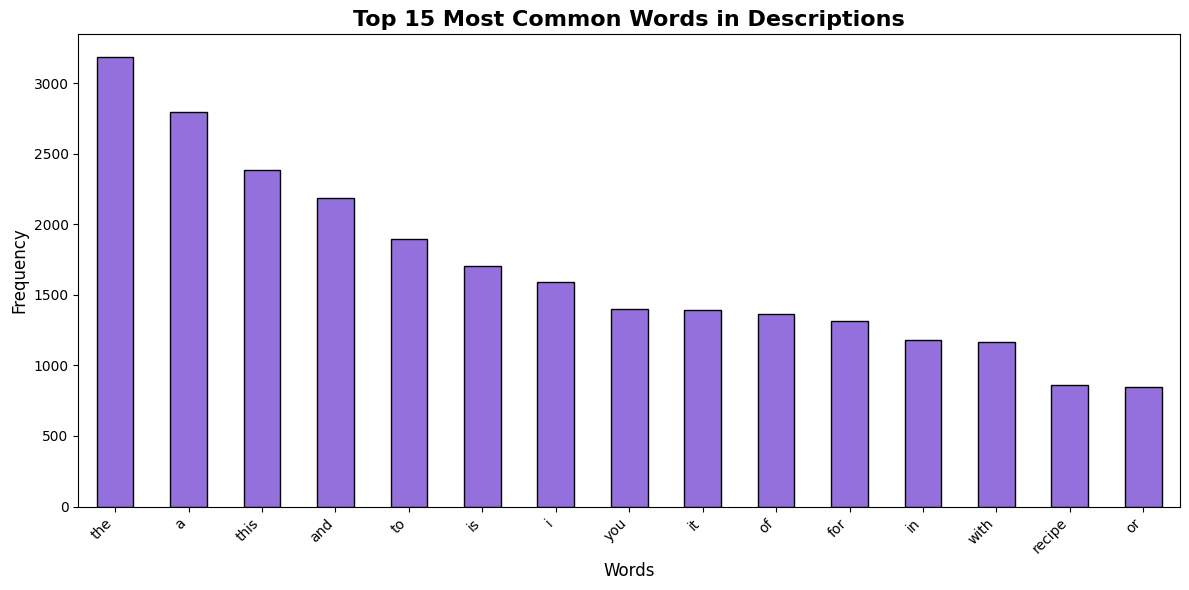

In [ ]:
# Steps words analysis with bar graph
flat_step_words = pd.Series([word.lower() for step_list in data['steps'] for step in step_list for word in step.split() if word not in [',', '.', '1', '2', '3']])
step_words_counts = flat_step_words.value_counts().head(15)

print("Top 15 Most Common Words in Steps:")
print(step_words_counts)
print()

# Create bar graph for steps words
plt.figure(figsize=(12, 6))
step_words_counts.plot(kind='bar', color='lightseagreen', edgecolor='black')
plt.title('Top 15 Most Common Words in Recipe Steps', fontsize=16, fontweight='bold')
plt.xlabel('Words', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Description words analysis with bar graph
flat_description_words = pd.Series([word.lower() for description in data['description'] for word in description.split()])
description_words_counts = flat_description_words.value_counts().head(15)

print("Top 15 Most Common Words in Descriptions:")
print(description_words_counts)
print()

# Create bar graph for description words
plt.figure(figsize=(12, 6))
description_words_counts.plot(kind='bar', color='mediumpurple', edgecolor='black')
plt.title('Top 15 Most Common Words in Descriptions', fontsize=16, fontweight='bold')
plt.xlabel('Words', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


As expected, quite a few stopwords. While these may provide little meaning, they are also a factor in authorship detection, since individuals have their writing particularities. Let us see how this goes per chef.

Top 10 Words per Chef in Steps:
      chef_id cleaned_steps_words  count  total_steps_words_per_chef  \
149      1533                 and   1622                       29130   
1809     1533                 the   1305                       29130   
888      1533                  in    836                       29130   
1857     1533                  to    820                       29130   
97       1533                   a    714                       29130   
2016     1533                with    555                       29130   
1932     1533               until    521                       29130   
1104     1533             minutes    445                       29130   
108      1533                 add    434                       29130   
850      1533                heat    345                       29130   
2244     3288                 and   2347                       43936   
4334     3288                 the   2331                       43936   
3169     3288                  i

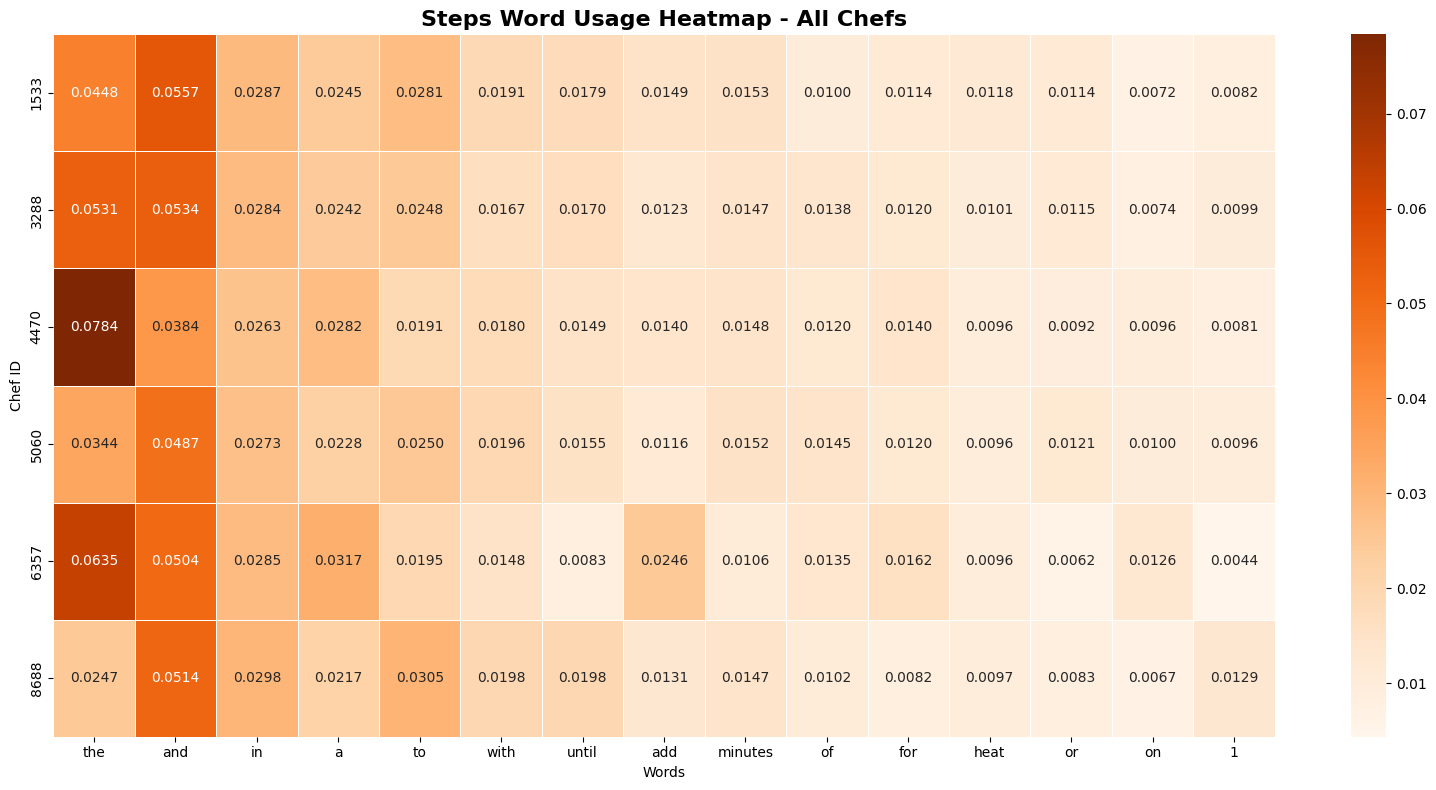

In [ ]:
# Chef steps words analysis with heatmap
chef_steps_words = data[['chef_id', 'steps']]

# Explode steps and then split words
chef_steps_words['steps_combined'] = chef_steps_words['steps'].apply(lambda x: ' '.join(x))
chef_steps_words['steps_words'] = chef_steps_words['steps_combined'].str.split()

chef_exploded_steps_words = chef_steps_words.explode('steps_words')

# Clean the words (remove punctuation and numbers)
chef_exploded_steps_words['cleaned_steps_words'] = chef_exploded_steps_words['steps_words'].str.lower().str.replace(r'[^\w\s]', '', regex=True)
chef_exploded_steps_words = chef_exploded_steps_words[chef_exploded_steps_words['cleaned_steps_words'].str.len() > 0]  # Remove empty space words

chef_steps_words_counts = chef_exploded_steps_words.groupby(['chef_id', 'cleaned_steps_words'], observed=True).size().reset_index(name='count')
chef_steps_words_full_count = chef_exploded_steps_words.groupby(['chef_id'], observed=True).size().reset_index(name='total_steps_words_per_chef')
chef_steps_words_counts = chef_steps_words_counts.merge(chef_steps_words_full_count, on='chef_id', how='left')
chef_steps_words_counts['normalized_count'] = chef_steps_words_counts['count']/chef_steps_words_counts['total_steps_words_per_chef']

top_chef_steps_words = chef_steps_words_counts.sort_values(["chef_id", "normalized_count"], ascending=[True, False]).groupby('chef_id', observed=True).head(10)


print("Top 10 Words per Chef in Steps:")
print(top_chef_steps_words)
print()

# Heatmap for steps words
chef_steps_words_pivot = chef_steps_words_counts.pivot_table(
    index='chef_id',
    columns='cleaned_steps_words',
    values='normalized_count',
    fill_value=0,
    observed=True
)

# Take top N most common words across all chefs
top_steps_words_across_chefs = chef_steps_words_pivot.mean().nlargest(15).index
chef_steps_words_pivot = chef_steps_words_pivot[top_steps_words_across_chefs]

plt.figure(figsize=(16, 8))
sns.heatmap(chef_steps_words_pivot, annot=True, cmap='Oranges', fmt='.4f', linewidths=0.5)
plt.title('Steps Word Usage Heatmap - All Chefs', fontsize=16, fontweight='bold')
plt.xlabel('Words')
plt.ylabel('Chef ID')
plt.tight_layout()
plt.show()


Top 10 Words per Chef in Descriptions:
      chef_id description_words  count  total_description_words_per_chef  \
1413     1533              this    227                              6112   
30       1533                 a    224                              6112   
74       1533               and    197                              6112   
1393     1533               the    188                              6112   
713      1533                 i    130                              6112   
1581     1533              with    117                              6112   
562      1533               for    105                              6112   
730      1533                is    105                              6112   
1430     1533                to     91                              6112   
733      1533                it     89                              6112   
1696     3288                 a    490                             11945   
3777     3288               the    459           

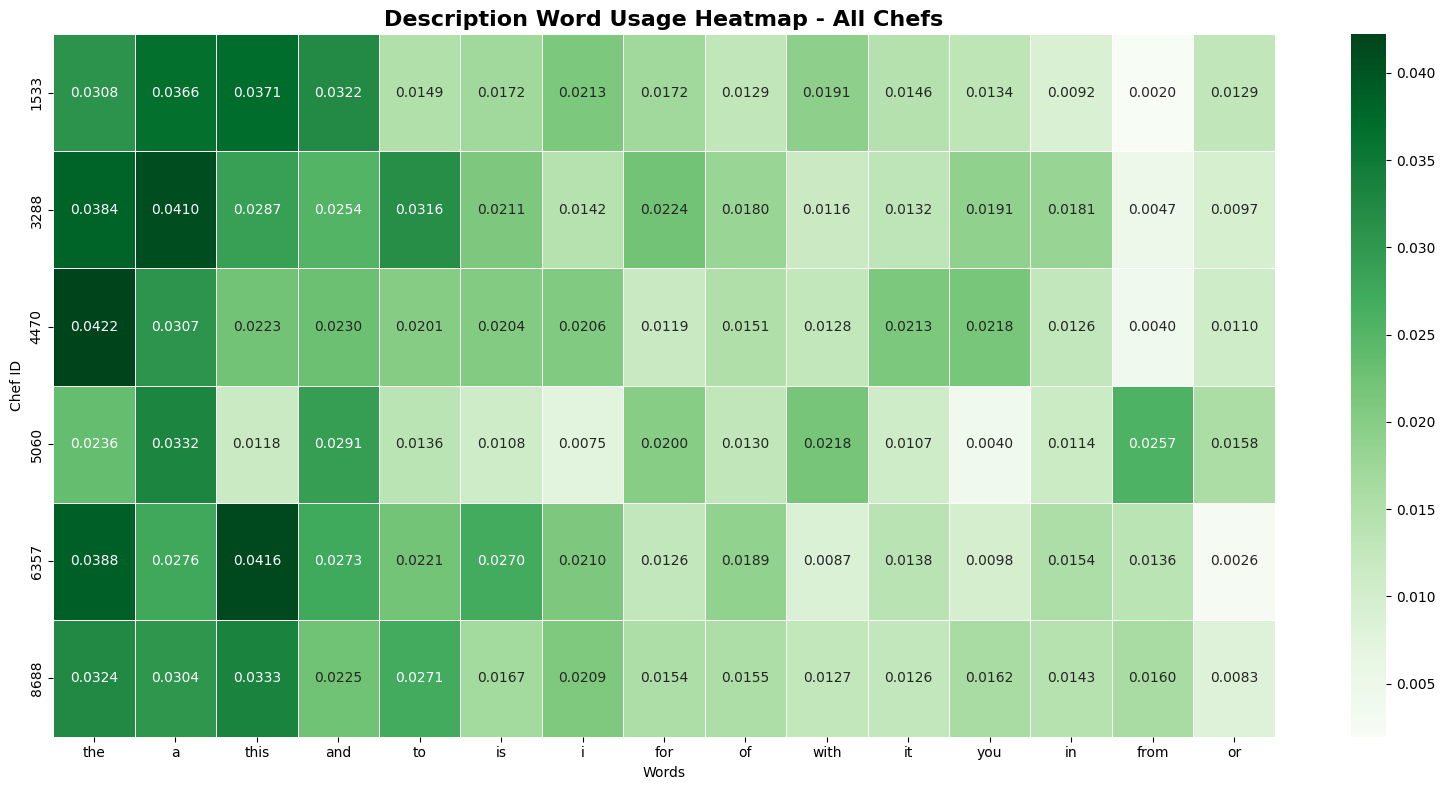

In [ ]:
# Chef description words analysis with heatmap
chef_description_words = data[['chef_id', 'description']]

chef_description_words['description_words'] = chef_description_words['description'].str.split()

chef_exploded_description_words = chef_description_words.explode('description_words')

chef_description_words_counts = chef_exploded_description_words.groupby(['chef_id', 'description_words'], observed=True).size().reset_index(name='count')
chef_description_words_full_count = chef_exploded_description_words.groupby(['chef_id'], observed=True).size().reset_index(name='total_description_words_per_chef')
chef_description_words_counts = chef_description_words_counts.merge(chef_description_words_full_count, on='chef_id', how='left')
chef_description_words_counts['normalized_count'] = chef_description_words_counts['count']/chef_description_words_counts['total_description_words_per_chef']

top_chef_description_words = chef_description_words_counts.sort_values(["chef_id", "normalized_count"], ascending=[True, False]).groupby('chef_id', observed=True).head(10)


print("Top 10 Words per Chef in Descriptions:")
print(top_chef_description_words)
print()

# Heatmap for description words
chef_desc_words_pivot = chef_description_words_counts.pivot_table(
    index='chef_id',
    columns='description_words',
    values='normalized_count',
    fill_value=0,
    observed=True
)

# Take top N most common words across all chefs for cleaner visualization
top_words_across_chefs = chef_desc_words_pivot.mean().nlargest(15).index
chef_desc_words_pivot = chef_desc_words_pivot[top_words_across_chefs]

plt.figure(figsize=(16, 8))
sns.heatmap(chef_desc_words_pivot, annot=True, cmap='Greens', fmt='.4f', linewidths=0.5)
plt.title('Description Word Usage Heatmap - All Chefs', fontsize=16, fontweight='bold')
plt.xlabel('Words')
plt.ylabel('Chef ID')
plt.tight_layout()
plt.show()

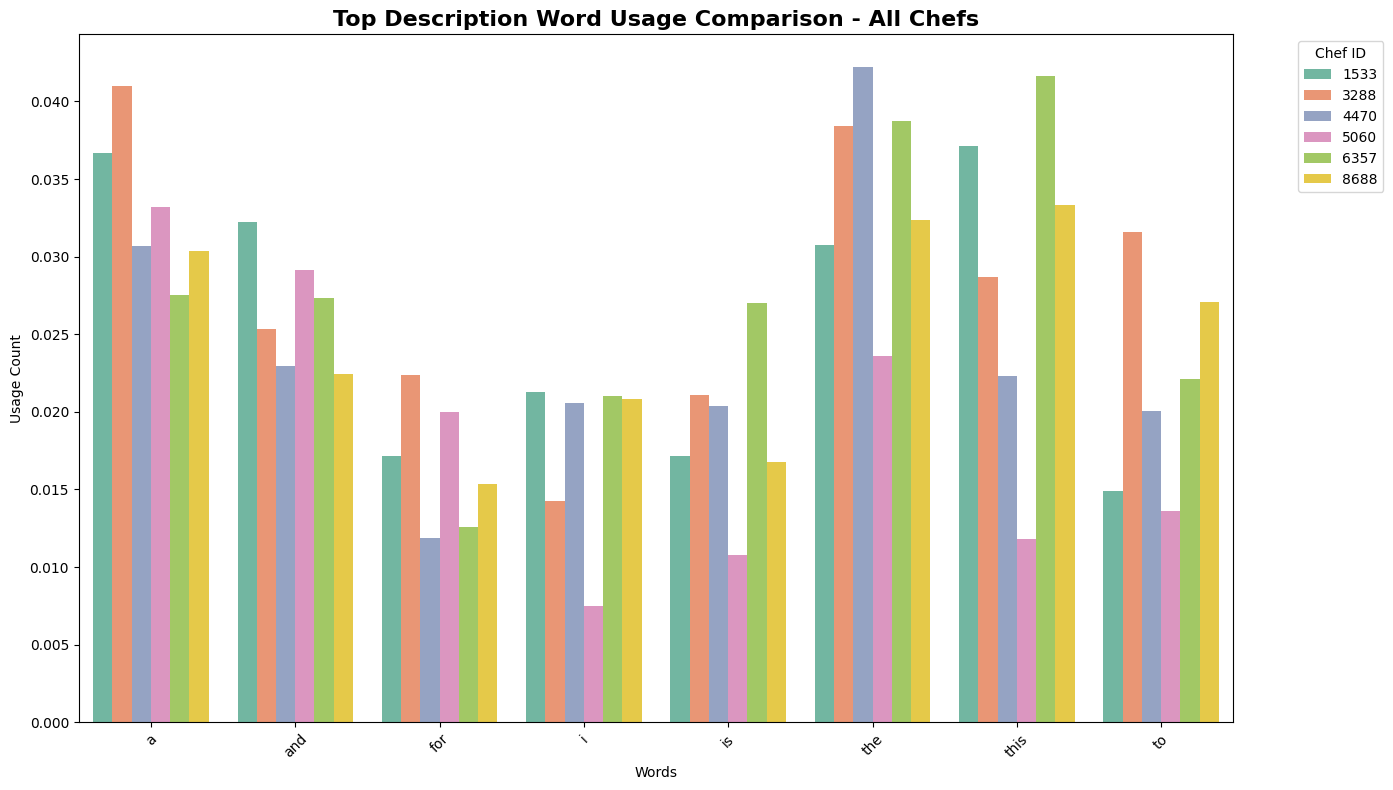

In [ ]:
# Grouped bar chart for top description words across chefs
top_words_all = chef_description_words_counts.groupby('description_words')['normalized_count'].mean().nlargest(8).index
filtered_desc_words = chef_description_words_counts[chef_description_words_counts['description_words'].isin(top_words_all)]

plt.figure(figsize=(14, 8))
sns.barplot(data=filtered_desc_words, x='description_words', y='normalized_count', hue='chef_id', palette='Set2')
plt.title('Top Description Word Usage Comparison - All Chefs', fontsize=16, fontweight='bold')
plt.xlabel('Words')
plt.ylabel('Usage Count')
plt.xticks(rotation=45)
plt.legend(title='Chef ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Again, as expected, stop words dominate.

Finally, let us look into recipe names. The most common words here may help indicate preferred dishes or ingredients.

Top 15 Most Common Words in Recipe Names:
with         453
and          358
chicken      260
salad        171
sauce        152
s            145
for          128
cheese       123
soup         115
rice          97
potato        93
tomato        90
garlic        86
casserole     82
chocolate     82
Name: count, dtype: int64



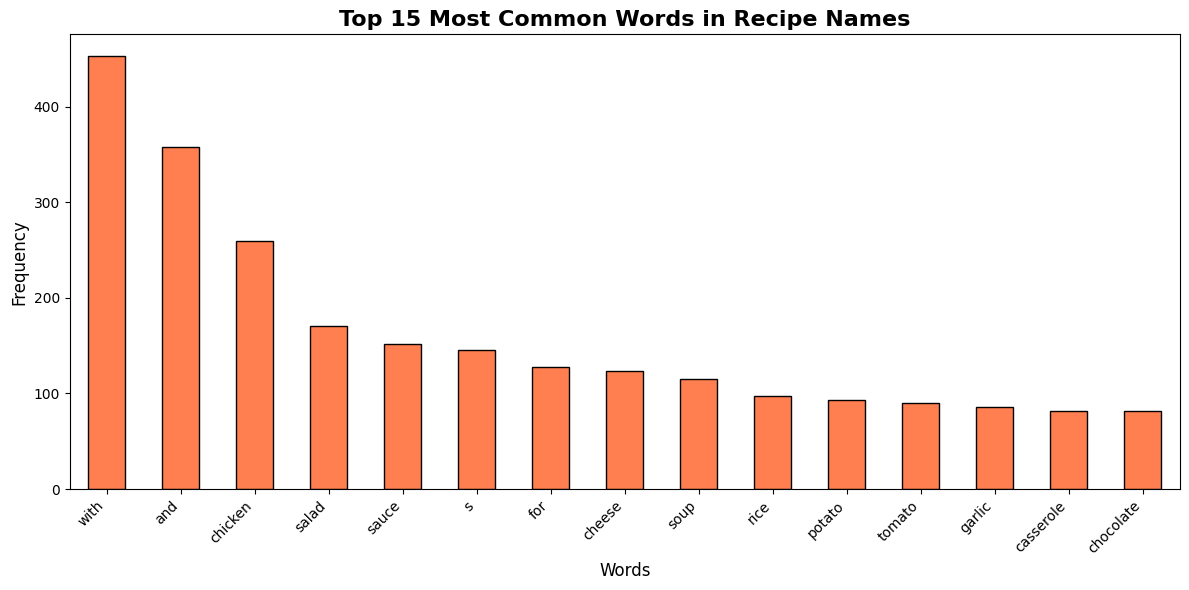

In [ ]:
# Recipe name words analysis with bar graph
flat_recipe_name_words = pd.Series([word.lower() for recipe_name in data['recipe_name'] for word in recipe_name.split()])
recipe_name_words_counts = flat_recipe_name_words.value_counts().head(15)

print("Top 15 Most Common Words in Recipe Names:")
print(recipe_name_words_counts)
print()

# Create bar graph for recipe name words
plt.figure(figsize=(12, 6))
recipe_name_words_counts.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Top 15 Most Common Words in Recipe Names', fontsize=16, fontweight='bold')
plt.xlabel('Words', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Top 10 Words per Chef in Recipe Names:
     chef_id recipename_words  count  total_recipename_words_per_chef  \
588     1533             with     67                             1658   
4       1533              and     40                             1658   
106     1533          chicken     26                             1658   
195     1533              fat     24                             1658   
322     1533              low     24                             1658   
466     1533            salad     23                             1658   
473     1533            sauce     21                             1658   
501     1533             soup     18                             1658   
100     1533           cheese     16                             1658   
387     1533           orange     16                             1658   
617     3288              and     85                             2015   
1247    3288             with     62                             2015   
727     3288

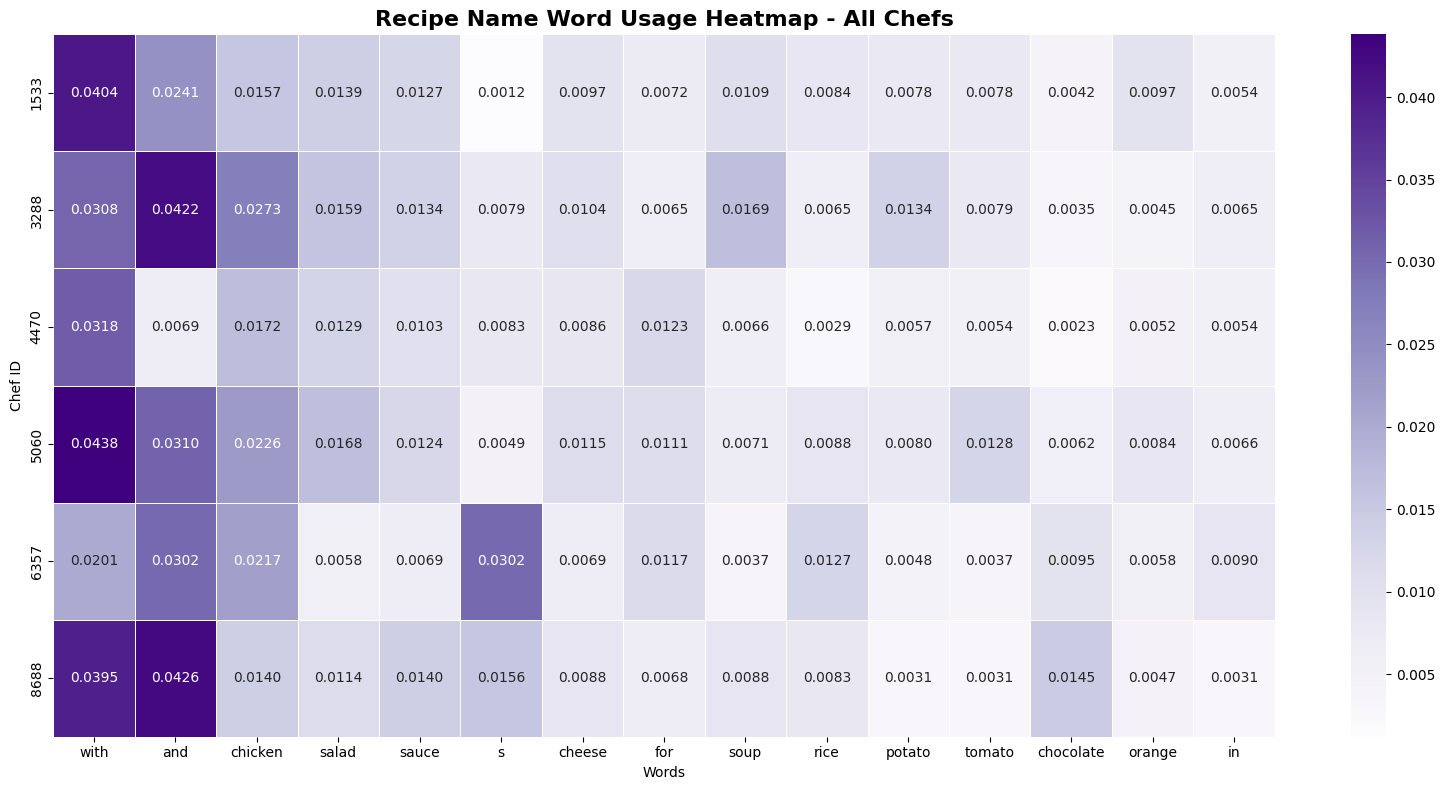

In [ ]:
# Chef recipe name words analysis with heatmap
chef_recipename_words = data[['chef_id', 'recipe_name']]

chef_recipename_words['recipename_words'] = chef_recipename_words['recipe_name'].str.split()

chef_exploded_recipename_words = chef_recipename_words.explode('recipename_words')

chef_recipename_words_counts = chef_exploded_recipename_words.groupby(['chef_id', 'recipename_words'], observed=True).size().reset_index(name='count')
chef_recipename_words_full_count = chef_exploded_recipename_words.groupby(['chef_id'], observed=True).size().reset_index(name='total_recipename_words_per_chef')
chef_recipename_words_counts = chef_recipename_words_counts.merge(chef_recipename_words_full_count, on='chef_id', how='left')
chef_recipename_words_counts['normalized_count'] = chef_recipename_words_counts['count']/chef_recipename_words_counts['total_recipename_words_per_chef']

top_chef_recipename_words = chef_recipename_words_counts.sort_values(["chef_id", "normalized_count"], ascending=[True, False]).groupby('chef_id', observed=True).head(10)


print("Top 10 Words per Chef in Recipe Names:")
print(top_chef_recipename_words)
print()

# Heatmap for recipe name words
chef_recipename_pivot = chef_recipename_words_counts.pivot_table(
    index='chef_id',
    columns='recipename_words',
    values='normalized_count',
    fill_value=0,
    observed=True
)

# Take top N most common words across all chefs for cleaner visualization
top_recipename_words_across_chefs = chef_recipename_pivot.mean().nlargest(15).index
chef_recipename_pivot = chef_recipename_pivot[top_recipename_words_across_chefs]

plt.figure(figsize=(16, 8))
sns.heatmap(chef_recipename_pivot, annot=True, cmap='Purples', fmt='.4f', linewidths=0.5)
plt.title('Recipe Name Word Usage Heatmap - All Chefs', fontsize=16, fontweight='bold')
plt.xlabel('Words')
plt.ylabel('Chef ID')
plt.tight_layout()
plt.show()

Again, quite a few commonalities. Chicken seems to be a frequent ingredient.

A final validation is to check for duplicates. For this purpose, we'll convert the list-like features back into strings in a copy of the dataset. This is because list-like features do not work with the .duplicated() method.

In [ ]:
data_w_strings = data.copy(deep=True)

data_w_strings['tags'] = data_w_strings['tags'].astype(str)
data_w_strings['steps'] = data_w_strings['steps'].astype(str)
data_w_strings['ingredients'] = data_w_strings['ingredients'].astype(str)

duplicate_idxs = data_w_strings[data_w_strings.duplicated()].index

It seems we have 14 instances which are entirely duplicated. These will be deleted since they disrupt the models by attributing a larger weight to repeated recipes.

In [ ]:
data = data.drop(index=duplicate_idxs)

Now that we have looked into a dataset and got an idea about it, we proceed to prepare it for modelling.

Applying lemmatization and removing stop words were a couple of attempted techniques. However, these resulted in worse scores. Therefore, they were not kept.

Since it's an authorship identification problem, one may argue that lemmatization, by reducing words to their lemma, removes chef-specific variations of words, turning them into a more common form. Additionally, removing stop words may provoke a similar effect, with stop words commonly used by a specific chef only being ommitted and thus losing such characteristic information.

In [ ]:
stop_words = ['this', 'a', 'and', 'the', 'i', 'for', 'is', 'to', 'it', 'you', 'in', 'of']

def tokenize_text_element(s):

    new_list = nltk.wordpunct_tokenize(s.lower())

    return [word for word in new_list if (word.isalpha() or word.isnumeric())] # Removed: lemmatizer.lemmatize() and word not in stop_words


def tokenize_list_of_text_elements(l):

    new_list = ' '.join(l)
    new_list = nltk.wordpunct_tokenize(new_list.lower())

    return [word for word in new_list if (word.isalpha() or word.isnumeric())] # Removed: lemmatizer.lemmatize() and word not in stop_words

def preprocess_dataset(data):

    data['tokenized_recipe_name'] = data['recipe_name'].apply(tokenize_text_element)
    data['tokenized_tags'] = data['tags'].apply(tokenize_list_of_text_elements)
    data['tokenized_steps'] = data['steps'].apply(tokenize_list_of_text_elements)
    data['tokenized_description'] = data['description'].apply(tokenize_text_element)
    data['tokenized_ingredients'] = data['ingredients'].apply(tokenize_list_of_text_elements)
    data['text'] = (data['tokenized_recipe_name'] + data['tokenized_tags'] + data['tokenized_steps'] + data['tokenized_description'] + data['tokenized_ingredients']).apply(' '.join)

    return data

data = preprocess_dataset(data)
data

,chef_id,recipe_name,data,tags,steps,description,ingredients,n_ingredients,tokenized_recipe_name,tokenized_tags,tokenized_steps,tokenized_description,tokenized_ingredients,text
0,5060,chefy s rice pudding,29/01/2002,"[60-minutes-or-less, time-to-make, course, mai...","[cook rice according to package directions, sc...","by request, from georgian bay gourmet.","[long grain rice, half-and-half cream, eggs, s...",6,"[chefy, s, rice, pudding]","[60, minutes, or, less, time, to, make, course...","[cook, rice, according, to, package, direction...","[by, request, from, georgian, bay, gourmet]","[long, grain, rice, half, and, half, cream, eg...",chefy s rice pudding 60 minutes or less time t...
1,3288,lasagna in the pressure cooker,14/12/2016,"[30-minutes-or-less, time-to-make, course, mai...","[in the opened pressure cooker , add the oil a...",i love how quickly i can put together a meal i...,"[olive oil, onion, ground beef, pasta sauce, w...",13,"[lasagna, in, the, pressure, cooker]","[30, minutes, or, less, time, to, make, course...","[in, the, opened, pressure, cooker, add, the, ...","[i, love, how, quickly, i, can, put, together,...","[olive, oil, onion, ground, beef, pasta, sauce...",lasagna in the pressure cooker 30 minutes or l...
2,5060,ham frittata,22/09/2004,"[60-minutes-or-less, time-to-make, course, mai...","[heat oven to 400f, heat oil in a non stick fr...",great for a quick meal with left over ham! lot...,"[olive oil, cooked ham, onion, red sweet bell ...",12,"[ham, frittata]","[60, minutes, or, less, time, to, make, course...","[heat, oven, to, heat, oil, in, a, non, stick,...","[great, for, a, quick, meal, with, left, over,...","[olive, oil, cooked, ham, onion, red, sweet, b...",ham frittata 60 minutes or less time to make c...
3,1533,red pepper garlic sauce,12/04/2005,"[15-minutes-or-less, time-to-make, course, mai...",[in a small mixing bowl mix all above ingredie...,this was so nice on salmon and we also have tr...,"[red peppers, garlic cloves, mayonnaise, salt ...",4,"[red, pepper, garlic, sauce]","[15, minutes, or, less, time, to, make, course...","[in, a, small, mixing, bowl, mix, all, above, ...","[this, was, so, nice, on, salmon, and, we, als...","[red, peppers, garlic, cloves, mayonnaise, sal...",red pepper garlic sauce 15 minutes or less tim...
4,5060,simple easy stuffed roast chicken with gravy ...,14/10/2004,"[time-to-make, course, main-ingredient, cuisin...","[preheat oven to 400f, empty contents of stuff...",this method can be used for roast chicken or t...,"[chicken flavor stuffing mix, hot water, butte...",13,"[simple, easy, stuffed, roast, chicken, with, ...","[time, to, make, course, main, ingredient, cui...","[preheat, oven, to, empty, contents, of, stuff...","[this, method, can, be, used, for, roast, chic...","[chicken, flavor, stuffing, mix, hot, water, b...",simple easy stuffed roast chicken with gravy f...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994,8688,cheesy potato skins,22/01/2007,"[60-minutes-or-less, time-to-make, course, mai...","[preheat oven to 400f, scrub the potatoes, wit...",love potato skins but don't need all the fat a...,"[russet potatoes, olive oil, paprika, salt, ca...",6,"[cheesy, potato, skins]","[60, minutes, or, less, time, to, make, course...","[preheat, oven, to, scrub, the, potatoes, with...","[love, potato, skins, but, don, t, need, all, ...","[russet, potatoes, olive, oil, paprika, salt, ...",cheesy potato skins 60 minutes or less time to...
2995,4470,bbq lamb with canadian whisky,10/03/2002,"[weeknight, time-to-make, main-ingredient, cui...","[in a bowl stir together the soy , whiskey and...",not only is canadian rye (whiskey) good as a d...,"[leg of lamb, brown sugar, canadian rye whisky...",4,"[bbq, lamb, with, canadian, whisky]","[weeknight, time, to, make, main, ingredient, ...","[in, a, bowl, stir, together, the, soy, whiske...","[not, only, is, canadian, rye, whiskey, good, ...","[leg, of, lamb, brown, sugar, canadian, rye, w...",bbq lamb with

With the dataset pre-processed, a copy with only the necessary features is made. Additionally, "data" is converted into the datetime format.

In [ ]:
data_train = data[['chef_id', 'text', 'data', 'n_ingredients']]
data_train['data'] = pd.to_datetime(data_train['data'], dayfirst=True)
data_train

,chef_id,text,data,n_ingredients
0,5060,chefy s rice pudding 60 minutes or less time t...,2002-01-29,6
1,3288,lasagna in the pressure cooker 30 minutes or l...,2016-12-14,13
2,5060,ham frittata 60 minutes or less time to make c...,2004-09-22,12
3,1533,red pepper garlic sauce 15 minutes or less tim...,2005-04-12,4
4,5060,simple easy stuffed roast chicken with gravy f...,2004-10-14,13
...,...,...,...,...
2994,8688,cheesy potato skins 60 minutes or less time to...,2007-01-22,6
2995,4470,bbq lamb with canadian whisky weeknight time t...,2002-03-10,4
2996,8688,coffee buttercream frosting 60 minutes or less...,2007-03-12,8
2997,5060,coriander dippin sauce 15 minutes or less time...,2002-02-26,3


We now define our X and y variables which contain, respectively, our features and our target.

In [ ]:
X = data_train[['text', 'data', 'n_ingredients']]
y = data_train['chef_id']


In order to process text computationally, it is pertinent to convert it into a numeric, summarized format, one which can be understood by machines and still encodes the information. Our text feature is thus vectorized using TF-IDF (Term Frequency - Inverse Document Frequency), which will take into account both the frequency of each word but also how common it is across documents, slightly disregarding common words.

A set of models and their hyperparameters is also defined. We'll initally model our problem using a Logistic Regression, a Support Vector Machine, a Multi-layer Perceptron, and a Random Forest. Their hyperparameter grids are defined in order to randomly sample 10 combinations of hyperparameters per model and select the best one.

In [ ]:
# TF-IDF vectorizer to be applied to the "text" feature
processor = ColumnTransformer([
    ("text", TfidfVectorizer(max_features=10000, min_df=2, ngram_range=(1,2)), "text")
])

# Hyperparameter combination options which will be sampled for each model
params_LR = {'model__solver': ['lbfgs', 'sag', 'saga'],
             'model__C': [0.01, 0.1, 0.5, 1, 5, 10],
             'model__class_weight':['balanced', None]}

params_SVC = {'model__C': [0.01, 0.1, 0.5, 1, 5, 10],
              'model__kernel': ['rbf','linear','sigmoid','poly'],
              'model__class_weight':['balanced', None]}

params_MLP = {'model__hidden_layer_sizes': [(32,), (32,32), (64,), (64,64)],
              'model__activation': ['logistic', 'tanh', 'relu'],
              'model__solver': ['lbfgs','adam', 'sgd'],
              'model__learning_rate': ['constant', 'invscaling', 'adaptive']}

params_RF = {'model__n_estimators': [50,100,200,300],
             'model__criterion': ['gini', 'entropy'],
             'model__max_depth': [3,4,5,7,8,10],
             'model__class_weight':['balanced', None]}

params = [params_LR, params_SVC, params_MLP, params_RF]

# Models which will be assessed with the parameter grids above
models = [LogisticRegression(max_iter=200, n_jobs=-1, random_state=42),
          SVC(random_state=42),
          MLPClassifier(max_iter=500, random_state=42),
          RandomForestClassifier(n_jobs=-1, random_state=42)]

# Variables to store best models' info (best parameters), fitted object, and socres
best_models_info = {}
best_models_estimators = {}
best_models_scores = {}

Now, we can define how our models are to be trained. A pipeline object is defined for the preprocessing and model stages. For modelling, we'll perform not only the above mentioned hyperparameter search, but also cross-validation with 5 folds. This will give us a better estimate of our models' performances.

The models' test scores will be stored for reference.

In [ ]:
# Function to train cross-validated models with and without hyperparameter search
def train_models(model, param):

  pipeline = Pipeline([("features", processor),
                       ("model", model)])

  if param is not None:

    # Randomized Search of hyperparameters for model cross-validation using accuracy as scoring method. 5 folds, 10 hyperparameters sets by default
    CV_search = RandomizedSearchCV(pipeline, param, n_jobs=-1, random_state=42)
    search = CV_search.fit(X, y)
    sorted_results = pd.DataFrame(search.cv_results_).sort_values(by=['rank_test_score'])

    # Retrieving cross-validated best parameters and their scores, along with the fitted model itself
    best_models_info[type(model).__name__] = {'params': search.best_params_,
                                              'mean_test_score': search.best_score_}
    best_models_estimators[type(model).__name__] = search.best_estimator_
    best_models_scores[type(model).__name__] = list(sorted_results.iloc[0][['split0_test_score','split1_test_score','split2_test_score','split3_test_score','split4_test_score']])

  else:

    # Cross-validation
    cv_results = cross_validate(pipeline, X, y, cv=5, n_jobs=-1)
    mean_test_score = cv_results['test_score'].mean()

    best_models_info[type(model).__name__] = {'params': None,
                                              'mean_test_score': mean_test_score}
    best_models_scores[type(model).__name__] = list(cv_results['test_score'])



In [ ]:
# Train models with cross-validation and randomized hyperparameter search/tuning
for model, param in zip(models,params):
  train_models(model, param)

# Display best models
pd.set_option('display.max_colwidth', None)
pd.DataFrame(best_models_info.values(), best_models_info.keys())

,params,mean_test_score
LogisticRegression,"{'model__solver': 'sag', 'model__class_weight': 'balanced', 'model__C': 10}",0.892462
SVC,"{'model__kernel': 'linear', 'model__class_weight': None, 'model__C': 5}",0.890787
MLPClassifier,"{'model__solver': 'adam', 'model__learning_rate': 'invscaling', 'model__hidden_layer_sizes': (32,), 'model__activation': 'logistic'}",0.892127
RandomForestClassifier,"{'model__n_estimators': 200, 'model__max_depth': 8, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}",0.803015


Now that we have the four best classifiers, one per kind of algorithm, we can train an ensemble of them, using hard majority voting.

By combining several models, ensembles frequently outperform the individual models.

In [ ]:
voting = VotingClassifier(
        estimators=[
            ('lr', LogisticRegression(solver='sag', class_weight='balanced', C=10, max_iter=200, n_jobs=-1, random_state=42)),
            ('svc', SVC(kernel='linear', class_weight=None, C=5, random_state=42)),
            ('mlp', MLPClassifier(solver='adam', learning_rate='invscaling', hidden_layer_sizes=(32,), activation='logistic', max_iter=500, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=200, max_depth=8, criterion='entropy', class_weight='balanced', n_jobs=-1, random_state=42))
        ],
        voting='hard'
    )

train_models(voting, None)

pd.DataFrame(best_models_info.values(), best_models_info.keys())

,params,mean_test_score
LogisticRegression,"{'model__solver': 'sag', 'model__class_weight': 'balanced', 'model__C': 10}",0.892462
SVC,"{'model__kernel': 'linear', 'model__class_weight': None, 'model__C': 5}",0.890787
MLPClassifier,"{'model__solver': 'adam', 'model__learning_rate': 'invscaling', 'model__hidden_layer_sizes': (32,), 'model__activation': 'logistic'}",0.892127
RandomForestClassifier,"{'model__n_estimators': 200, 'model__max_depth': 8, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}",0.803015
VotingClassifier,None,0.896482


In [ ]:
pd.reset_option('display.max_colwidth')

Our ensemble model proves to be superior. From this analysis, this will be the model to choose out of the five.

Another pre-processing approach is attempted. Instead of classical tokenization and vectorization methods, we'll use DistilBERT to generate our text's embeddings. We'll then train the same models as above, with the same hyperparameters, and assess which are superior.

The first step is to adapt the text to a more logical ordering of the text. Since we have distinct information, it is relevant to mark their separation. This will should help DistilBERT understand the conceptual groups of information.

In [ ]:
bert_data_train = data[['chef_id', 'recipe_name', 'data', 'tags', 'steps', 'description', 'ingredients', 'n_ingredients']].copy(deep=True)

def combine_text(row):
    recipe_name = f"Recipe Name: {row['recipe_name']}"
    tags = f"Tags: {', '.join(row['tags'])}"
    date = f"Date: {row['data']}"
    steps = f"Steps: {' '.join(row['steps'])}"
    desc = f"Description: {row['description']}"
    ingredients = f"Ingredients: {' '.join(row['ingredients'])}"
    n_ingredients = f"Number of ingredients: {row['n_ingredients']}"
    return f"{recipe_name}. {tags}. {date}. {steps}. {desc}. {ingredients}. {n_ingredients}"

bert_data_train["text"] = bert_data_train.apply(combine_text, axis=1)

bert_data_train

,chef_id,recipe_name,data,tags,steps,description,ingredients,n_ingredients,text
0,5060,chefy s rice pudding,29/01/2002,"[60-minutes-or-less, time-to-make, course, mai...","[cook rice according to package directions, sc...","by request, from georgian bay gourmet.","[long grain rice, half-and-half cream, eggs, s...",6,Recipe Name: chefy s rice pudding. Tags: 60-mi...
1,3288,lasagna in the pressure cooker,14/12/2016,"[30-minutes-or-less, time-to-make, course, mai...","[in the opened pressure cooker , add the oil a...",i love how quickly i can put together a meal i...,"[olive oil, onion, ground beef, pasta sauce, w...",13,Recipe Name: lasagna in the pressure cooker. T...
2,5060,ham frittata,22/09/2004,"[60-minutes-or-less, time-to-make, course, mai...","[heat oven to 400f, heat oil in a non stick fr...",great for a quick meal with left over ham! lot...,"[olive oil, cooked ham, onion, red sweet bell ...",12,Recipe Name: ham frittata. Tags: 60-minutes-or...
3,1533,red pepper garlic sauce,12/04/2005,"[15-minutes-or-less, time-to-make, course, mai...",[in a small mixing bowl mix all above ingredie...,this was so nice on salmon and we also have tr...,"[red peppers, garlic cloves, mayonnaise, salt ...",4,Recipe Name: red pepper garlic sauce. Tags: 15...
4,5060,simple easy stuffed roast chicken with gravy ...,14/10/2004,"[time-to-make, course, main-ingredient, cuisin...","[preheat oven to 400f, empty contents of stuff...",this method can be used for roast chicken or t...,"[chicken flavor stuffing mix, hot water, butte...",13,Recipe Name: simple easy stuffed roast chicken...
...,...,...,...,...,...,...,...,...,...
2994,8688,cheesy potato skins,22/01/2007,"[60-minutes-or-less, time-to-make, course, mai...","[preheat oven to 400f, scrub the potatoes, wit...",love potato skins but don't need all the fat a...,"[russet potatoes, olive oil, paprika, salt, ca...",6,Recipe Name: cheesy potato skins. Tags: 60-min...
2995,4470,bbq lamb with canadian whisky,10/03/2002,"[weeknight, time-to-make, main-ingredient, cui...","[in a bowl stir together the soy , whiskey and...",not only is canadian rye (whiskey) good as a d...,"[leg of lamb, brown sugar, canadian rye whisky...",4,Recipe Name: bbq lamb with canadian whisky. Ta...
2996,8688,coffee buttercream frosting,12/03/2007,"[60-minutes-or-less, time-to-make, course, pre...","[beat cream , sugar , hot coffee , egg yolks a...",i discovered this recipe in lee lee's recipe b...,"[whipping cream, sugar, strong coffee, egg yol...",8,Recipe Name: coffee buttercream frosting. Tags...
2997,5060,coriander dippin sauce,26/02/2002,"[15-minutes-or-less, time-to-make, course, cui...","[in a small bowl combine yogurt , coriander an...",good for dippin anything but best with recipe ...,"[low-fat plain yogurt, fresh coriander leaves,...",3,Recipe Name: coriander dippin sauce. Tags: 15-...


Now, we use DistilBERT from Hugging Face's public models to generate the text's embeddings.

In [ ]:
# Load DistilBERT tokenizer and model
bert_tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')
bert_model = AutoModel.from_pretrained('distilbert-base-uncased')

def get_embedding(text):
    inputs = bert_tokenizer(text,
                       return_tensors="pt",
                       truncation=True,
                       padding=True,
                       max_length=512)

    with torch.no_grad():
        outputs = bert_model(**inputs)

    embedding = outputs.last_hidden_state[:, 0, :].squeeze().numpy()

    return embedding


embeddings = []
for text in bert_data_train["text"]:
    embedding = get_embedding(text)
    embeddings.append(embedding)

bert_data_train["embedding"] = embeddings

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Again, we define our X (features) and y (target).

In [ ]:
X = np.array(bert_data_train["embedding"].tolist())
y = np.array(bert_data_train['chef_id'].tolist())

Our best classifiers are defined below. As previously mentioned, they share the same hyperparameters as the best classifiers obtained with classical text pre-processing techniques.

In [ ]:
best_models = [LogisticRegression(solver='sag',
                             class_weight='balanced',
                             C=10,
                             max_iter=200,
                             n_jobs=-1,
                             random_state=42),
          SVC(kernel='linear',
              class_weight=None,
              C=5,
              random_state=42),
          MLPClassifier(solver='adam',
                        learning_rate='invscaling',
                        hidden_layer_sizes=(32,),
                        activation='logistic',
                        max_iter=500,
                        random_state=42),
          RandomForestClassifier(n_estimators=200,
                                 max_depth=8,
                                 criterion='entropy',
                                 class_weight='balanced',
                                 n_jobs=-1,
                                 random_state=42),
          VotingClassifier(estimators=[('lr', LogisticRegression(solver='sag',
                                                                 class_weight='balanced',
                                                                 C=10,
                                                                 max_iter=200,
                                                                 n_jobs=-1,
                                                                 random_state=42)),
                                       ('svc', SVC(kernel='linear',
                                                   class_weight=None,
                                                   C=5,
                                                   random_state=42)),
                                       ('mlp', MLPClassifier(solver='adam',
                                                             learning_rate='invscaling',
                                                             hidden_layer_sizes=(32,),
                                                             activation='logistic',
                                                             max_iter=500,
                                                             random_state=42)),
                                       ('rf', RandomForestClassifier(n_estimators=200,
                                                                     max_depth=8,
                                                                     criterion='entropy',
                                                                     class_weight='balanced',
                                                                     n_jobs=-1,
                                                                     random_state=42))],
                           voting='hard')]

Again, a function is defined for training the models. They will be trained and assessed via 5-fold cross-validation and their test scores will be stored.

In [ ]:
def train_bert_model(model):

  model_name = type(model).__name__

  bert_model_cv_results = cross_validate(model, X, y, cv=5, n_jobs=-1)
  bert_model_mean_test_score = bert_model_cv_results['test_score'].mean()

  best_models_info['Bert ' + model_name] = {'params': best_models_info[model_name]['params'], # The models share the same parameters as their non-BERT embedded counterparts
                                            'mean_test_score': bert_model_mean_test_score}
  best_models_scores['Bert ' + model_name] = list(bert_model_cv_results['test_score'])

In [ ]:
for model in best_models:
  train_bert_model(model)

pd.set_option('display.max_colwidth', None)
pd.DataFrame(best_models_info.values(), best_models_info.keys())

,params,mean_test_score
LogisticRegression,"{'model__solver': 'sag', 'model__class_weight': 'balanced', 'model__C': 10}",0.892462
SVC,"{'model__kernel': 'linear', 'model__class_weight': None, 'model__C': 5}",0.890787
MLPClassifier,"{'model__solver': 'adam', 'model__learning_rate': 'invscaling', 'model__hidden_layer_sizes': (32,), 'model__activation': 'logistic'}",0.892127
RandomForestClassifier,"{'model__n_estimators': 200, 'model__max_depth': 8, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}",0.803015
VotingClassifier,None,0.896482
Bert LogisticRegression,"{'model__solver': 'sag', 'model__class_weight': 'balanced', 'model__C': 10}",0.857286
Bert SVC,"{'model__kernel': 'linear', 'model__class_weight': None, 'model__C': 5}",0.845896
Bert MLPClassifier,"{'model__solver': 'adam', 'model__learning_rate': 'invscaling', 'model__hidden_layer_sizes': (32,), 'model__activation': 'logistic'}",0.850921
Bert RandomForestClassifier,"{'model__n_estimators': 200, 'model__max_depth': 8, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}",0.704523
Bert VotingClassifier,None,0.853601


In [ ]:
pd.reset_option('display.max_colwidth')

Again, our best model has proven to be the Voting Classifier using more classical pre-processing techniques. This is the model we'll use to make our final predictions.

It is interesting to note that using DistilBERT proves to be hindering.

Before we move on, however, it is pertinent to understand whether the results of each type of model using, or not, DistilBERT for embedding are statistically significantly superior.

We must note that we have a very small sample size, so the reliability of these methods is not ideal.

We start by assessing whether the differences in performance between pairs of models are normally distributed. Depending on that results, we perform either a paired t-test, or a Wilcoxon signed-rank test.

The tests below assess the following hypotheses:

- Student's t-test:

  - H0: The mean of results of one model is equal to that of the other model.
  - H1: The mean of results of one model (the one without BERT) is greather than that of the other model.

- Wilcoxon signed-rank test:

  - H0: the results' paired differences are symmetric about a mean of 0
  - H1: the results' paired differences are symmetric about a mean greater than 0

In general terms, failing to reject the null hypotheses (p-value > 0.05), would indicate there is **no** evidence to indicate the results center around a mean which is different from the other model's results' mean.
However, rejecting it would suggest evidence that the model without BERT produces results with a mean greater than that of the same model without BERT.

In [ ]:
pair_wise_results = {'Logistic Regression': (best_models_scores['LogisticRegression'], best_models_scores['Bert LogisticRegression']),
                     'SVC': (best_models_scores['SVC'], best_models_scores['Bert SVC']),
                     'MLP': (best_models_scores['MLPClassifier'], best_models_scores['Bert MLPClassifier']),
                     'Random Forest': (best_models_scores['RandomForestClassifier'], best_models_scores['Bert RandomForestClassifier']),
                     'Voting Classifier': (best_models_scores['VotingClassifier'], best_models_scores['Bert VotingClassifier'])}

In [ ]:
for model, pair_results in pair_wise_results.items():

  diffs = np.array(pair_results[0]) - np.array(pair_results[1])

  p_normal_diffs = stats.shapiro(diffs)

  if p_normal_diffs[1] < 0.05:
    test_result = stats.wilcoxon(pair_results[0], pair_results[1], alternative='greater')
    p_value = test_result[1]
  else:
    test_result = stats.ttest_rel(pair_results[0], pair_results[1], alternative='greater')
    p_value = test_result[1]

  if p_value < 0.05:
    print(f'The statiscal test, with a p-value of {round(p_value,5)}, indicates that for model {model} there is evidence to suggest that not using BERT results in a greater mean score.')
  else:
    print(f'The statiscal test, with a p-value of {round(p_value,5)}, indicates that for model {model} there is evidence to suggest that using, or not, BERT results in the same mean score.')

The statiscal test, with a p-value of 0.00141, indicates that for model Logistic Regression there is evidence to suggest that not using BERT results in a greater mean score.
The statiscal test, with a p-value of 0.00045, indicates that for model SVC there is evidence to suggest that not using BERT results in a greater mean score.
The statiscal test, with a p-value of 0.00012, indicates that for model MLP there is evidence to suggest that not using BERT results in a greater mean score.
The statiscal test, with a p-value of 0.00023, indicates that for model Random Forest there is evidence to suggest that not using BERT results in a greater mean score.
The statiscal test, with a p-value of 0.00068, indicates that for model Voting Classifier there is evidence to suggest that not using BERT results in a greater mean score.


As expected, given the magnitude of score differences, our statistical texts indicate that not using DistilBERT is beneficial in our specific endeavor.

With our best model clear and defined, it is in the best interest to understand where it underperforms and why. Therefore, it will be trained on a portion of the data and the misclassifications will be assessed.

In [ ]:
best_model = VotingClassifier(estimators=[('lr', LogisticRegression(solver='sag',
                                                                 class_weight='balanced',
                                                                 C=10,
                                                                 max_iter=200,
                                                                 n_jobs=-1,
                                                                 random_state=42)),
                                       ('svc', SVC(kernel='linear',
                                                   class_weight=None,
                                                   C=5,
                                                   random_state=42)),
                                       ('mlp', MLPClassifier(solver='adam',
                                                             learning_rate='invscaling',
                                                             hidden_layer_sizes=(32,),
                                                             activation='logistic',
                                                             max_iter=500,
                                                             random_state=42)),
                                       ('rf', RandomForestClassifier(n_estimators=200,
                                                                     max_depth=8,
                                                                     criterion='entropy',
                                                                     class_weight='balanced',
                                                                     n_jobs=-1,
                                                                     random_state=42))],
                           voting='hard')

In [ ]:
X = data_train[['text', 'data', 'n_ingredients']]
y = data_train['chef_id']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

              precision    recall  f1-score   support

        1533       0.75      0.75      0.75        80
        3288       0.84      0.84      0.84        90
        4470       0.93      0.96      0.94       160
        5060       0.99      0.93      0.96       107
        6357       0.99      0.93      0.96        73
        8688       0.80      0.86      0.83        87

    accuracy                           0.89       597
   macro avg       0.88      0.88      0.88       597
weighted avg       0.89      0.89      0.89       597



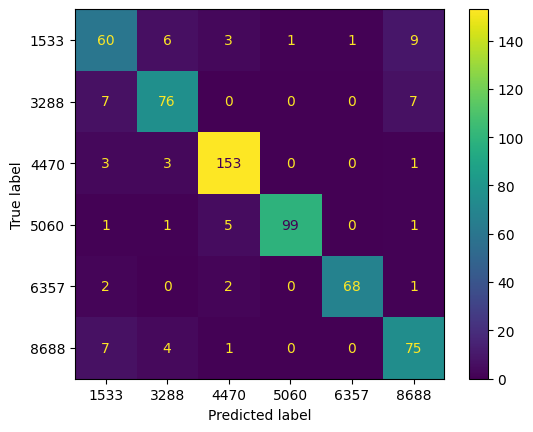

In [ ]:
pipeline = Pipeline([
      ("features", processor),
      ("model", best_model)])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_val)

print(classification_report(y_val, y_pred))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
plt.show()

From the data above, it is clear that our model performs better on the more common classes. A common consequence of imbalanced data. However, it is most interesting to note that the model is also quite effective in predicting the least common class. It is likely that this class is quite distinctive of the others.

Additionally, we note that the many misclassifications (40 out of 66) come from the model confusing chefs 1533 and 3288 between each other, and both with chef 8688.

In order to study the results further, the misclassifications are retrieved and analyzed.

In [ ]:
val_dataset = X_val.copy(deep=True)
val_dataset['chef_id'] = y_val
val_dataset['predicted_chef_id'] = y_pred
val_dataset['correct_prediction'] = (val_dataset['chef_id']==val_dataset['predicted_chef_id'])
incorrect_predictions = val_dataset[val_dataset['correct_prediction']==False]

Now, we fetch the data in the initial format so we can assess the text features separately.

In [ ]:
misclassified_data = incorrect_predictions.join(data, how='left', rsuffix='original').drop(['text','data','n_ingredients','chef_idoriginal','correct_prediction',
                                                                                            'tokenized_recipe_name', 'tokenized_tags', 'tokenized_steps',
                                                                                            'tokenized_description', 'tokenized_ingredients',
                                                                                            'textoriginal'], axis=1)

In [ ]:
misclassified_data

,chef_id,predicted_chef_id,recipe_name,dataoriginal,tags,steps,description,ingredients,n_ingredientsoriginal
696,1533,8688,brownie macaroon pudding cake,31/12/2003,"[60-minutes-or-less, time-to-make, course, mai...","[heat oven to 350 degrees, in medium bowl comb...",every forkful is coconut and chocolate in fudg...,"[all-purpose flour, sugar, unsweetened cocoa, ...",11
1883,4470,1533,cranberry applesauce scones,06/11/2001,"[60-minutes-or-less, time-to-make, course, mai...","[preheat oven to 425f, combine the first 5 ing...",these scones freeze well. nice on a festive br...,"[flour, salt, baking powder, baking soda, suga...",10
182,6357,8688,gourmet belgian hot chocolate,18/12/2002,"[30-minutes-or-less, time-to-make, course, mai...",[start off by mixing together the milk and the...,this hot chocolate recipe is a sumptuous belgi...,"[milk, vanilla bean, bittersweet chocolate]",3
935,4470,8688,special chocolate cheesecake,26/08/2004,"[time-to-make, course, preparation, for-large-...","[crust:, combine crumbs& butter and press onto...",my neighbor gave me this recipe saying this is...,"[chocolate wafer, butter, cream cheese, sugar,...",9
1008,8688,3288,tortellini with white wine primavera,18/12/2005,"[60-minutes-or-less, time-to-make, course, mai...","[set a pot of the water on high heat to boil ,...","who does not like pasta?? we love it, and espe...","[cheese tortellini, plum tomatoes, green bell ...",16
...,...,...,...,...,...,...,...,...,...
2197,1533,3288,lemon wild rice risotto,31/10/2002,"[weeknight, time-to-make, course, main-ingredi...","[wash wild rice carefully and drain, in a larg...","add a bottle of wine, a fresh green salad and ...","[wild rice, butter, onion, chicken broth, saff...",19
2417,3288,8688,penne with asparagus lemon sauce,15/09/2002,"[60-minutes-or-less, time-to-make, course, mai...",[snap the tough butt ends off the asparagus or...,take advantage of the seasonal bounty of aspar...,"[fresh asparagus, water, sea salt, lemon, extr...",8
2915,1533,3288,artichoke heart dip,23/11/1999,"[30-minutes-or-less, time-to-make, course, mai...","[cut artichoke hearts into small pieces, mix a...",people usually rave about this one!,"[mayonnaise, parmesan cheese, water-packed art...",5
1079,6357,4470,umm ali,15/08/2003,"[60-minutes-or-less, time-to-make, course, pre...","[boil milk in a large pot, add sugar to it, mi...",courtesy: boulvar,"[puff pastry, milk, cinnamon, sultanas, sliced...",7


In [ ]:
chef_tag_counts = misclassified_data[['chef_id', 'tags']].explode('tags').groupby(['chef_id', 'tags'], observed=False).size().reset_index(name='count')

chef_tag_counts.sort_values(["chef_id", "count"], ascending=[True, False]).groupby('chef_id', observed=False).head(10)

,chef_id,tags,count
55,1533,course,20
150,1533,preparation,20
195,1533,time-to-make,19
62,1533,dietary,18
114,1533,main-ingredient,18
70,1533,equipment,17
130,1533,occasion,11
188,1533,stove-top,9
201,1533,vegetables,9
6,1533,60-minutes-or-less,7


The misclassfied tags do not seem to provide any clues.

In [ ]:
chef_ingredient_counts = misclassified_data[['chef_id', 'ingredients']].explode('ingredients').groupby(['chef_id', 'ingredients'], observed=False).size().reset_index(name='count')

chef_ingredient_counts.sort_values(["chef_id", "count"], ascending=[True, False]).groupby('chef_id', observed=False).head(10)

,chef_id,ingredients,count
283,1533,salt,9
309,1533,sugar,7
49,1533,butter,5
230,1533,olive oil,4
242,1533,parmesan cheese,4
2,1533,all-purpose flour,3
147,1533,fresh parsley,3
174,1533,ground cinnamon,3
217,1533,milk,3
231,1533,onion,3


An interesting note regarding ingredients is how chef 1533 does not use sugar that many times, yet that ingredient is more common in misclassifications. And chef 8688 uses sugar quite frequently, but not as much in misclassifications. However, garlic is frequent. As it is for chef 1533's recipes in general. This would be a possible explanation for the confusion between the two, for example.

In [ ]:
chef_exploded_steps = misclassified_data[['chef_id', 'steps']].explode('steps')

chef_exploded_steps['step_words'] = chef_exploded_steps['steps'].str.split()

chef_exploded_step_words = chef_exploded_steps.explode('step_words')

chef_exploded_step_words = chef_exploded_step_words[~chef_exploded_step_words['step_words'].isin([',', '.', '1', '2', '3'])]

chef_step_words_counts = chef_exploded_step_words.groupby(['chef_id', 'step_words'], observed=False).size().reset_index(name='count')

chef_step_words_counts.sort_values(["chef_id", "count"], ascending=[True, False]).groupby('chef_id', observed=False).head(10)

,chef_id,step_words,count
93,1533,and,105
980,1533,the,100
506,1533,in,56
1007,1533,to,49
60,1533,a,47
1045,1533,until,41
659,1533,or,34
69,1533,add,33
1089,1533,with,30
607,1533,minutes,28


When it comes to step words, it is interesting to note that chef 6357 comes up with the word "minutes" more frequently. This word is common across the other chefs, but not this one, so it might have fueled the few misclassifications of this chef.

In [ ]:
chef_description_words = misclassified_data[['chef_id', 'description']]

chef_description_words['description_words'] = chef_description_words['description'].str.split()

chef_exploded_description_words = chef_description_words.explode('description_words')

chef_description_words_counts = chef_exploded_description_words.groupby(['chef_id', 'description_words'], observed=False).size().reset_index(name='count')

chef_description_words_counts.sort_values(["chef_id", "count"], ascending=[True, False]).groupby('chef_id', observed=False).head(10)

,chef_id,description_words,count
8,1533,a,12
29,1533,and,12
499,1533,this,10
251,1533,i,8
260,1533,is,6
261,1533,it,5
492,1533,the,5
40,1533,are,4
201,1533,for,4
300,1533,made,4


Contrary to step words, description words do not seem to give any particular clue.

In [ ]:
chef_recipename_words = misclassified_data[['chef_id', 'recipe_name']]

chef_recipename_words['recipename_words'] = chef_recipename_words['recipe_name'].str.split()

chef_exploded_recipename_words = chef_recipename_words.explode('recipename_words')

chef_recipename_words_counts = chef_exploded_recipename_words.groupby(['chef_id', 'recipename_words'], observed=False).size().reset_index(name='count')

chef_recipename_words_counts.sort_values(["chef_id", "count"], ascending=[True, False]).groupby('chef_id', observed=False).head(10)

,chef_id,recipename_words,count
191,1533,with,5
143,1533,salad,4
10,1533,artichoke,2
36,1533,blueberry,2
102,1533,lemon,2
132,1533,pot,2
137,1533,rice,2
0,1533,a,1
5,1533,and,1
7,1533,apple,1


Finally, recipe names also do not seem to induce any inquisitive thought, as counts are few and thus less indicative.

Now, the last step: making our predictions.

We start by training the model on the full dataset. We reinstatiate the model for a full refitting process.

In [ ]:
X = data_train[['text', 'data', 'n_ingredients']]
y = data_train['chef_id']

In [ ]:
best_model = VotingClassifier(estimators=[('lr', LogisticRegression(solver='sag',
                                                                 class_weight='balanced',
                                                                 C=10,
                                                                 max_iter=200,
                                                                 n_jobs=-1,
                                                                 random_state=42)),
                                       ('svc', SVC(kernel='linear',
                                                   class_weight=None,
                                                   C=5,
                                                   random_state=42)),
                                       ('mlp', MLPClassifier(solver='adam',
                                                             learning_rate='invscaling',
                                                             hidden_layer_sizes=(32,),
                                                             activation='logistic',
                                                             max_iter=500,
                                                             random_state=42)),
                                       ('rf', RandomForestClassifier(n_estimators=200,
                                                                     max_depth=8,
                                                                     criterion='entropy',
                                                                     class_weight='balanced',
                                                                     n_jobs=-1,
                                                                     random_state=42))],
                           voting='hard')

In [ ]:
pipeline = Pipeline([
      ("features", processor),
      ("model", best_model)])

pipeline.fit(X, y)

Pipeline(steps=[('features',
                 ColumnTransformer(transformers=[('text',
                                                  TfidfVectorizer(max_features=10000,
                                                                  min_df=2,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'text')])),
                ('model',
                 VotingClassifier(estimators=[('lr',
                                               LogisticRegression(C=10,
                                                                  class_weight='balanced',
                                                                  max_iter=200,
                                                                  n_jobs=-1,
                                                                  random_state=42,
                                                                  solver='sag')),
                                              ('svc',
                                               SVC(C=5, kernel='linear',
                                                   random_state=42)),
                                              ('mlp',
                                               MLPClassifier(activation='logistic',
                                                             hidden_layer_sizes=(32,),
                                                             learning_rate='invscaling',
                                                             max_iter=500,
                                                             random_state=42)),
                                              ('rf',
                                               RandomForestClassifier(class_weight='balanced',
                                                                      criterion='entropy',
                                                                      max_depth=8,
                                                                      n_estimators=200,
                                                                      n_jobs=-1,
                                                                      random_state=42))]))])

We now import and process the test dataset.

In [ ]:
data_test = pd.read_csv('test-no-labels.csv', delimiter=';')

for col in ['tags', 'steps', 'ingredients']:
    data_test[col] = data_test[col].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else [])

data_test

,recipe_name,data,tags,steps,description,ingredients,n_ingredients
0,gaaaaarlic jelly,16/11/2001,"[30-minutes-or-less, time-to-make, course, cui...","[in a large saucepan combine butter& garlic, c...",if you like you can add a drop of food colorin...,"[butter, garlic, sugar, apple cider vinegar, l...",5
1,brie crisps,11/12/2003,"[30-minutes-or-less, time-to-make, course, mai...",[combine butter and cheese in the food process...,"easy and fast to make, everyone loves them.","[brie cheese, butter, flour, cayenne pepper, s...",6
2,coconut draped peanuty banana,08/04/2002,"[15-minutes-or-less, time-to-make, course, mai...","[slice banana in half lengthwise, put peanut b...",protein - here i get you!,"[peanut butter, banana, flaked coconut]",3
3,stuffed idlis,12/03/2003,"[60-minutes-or-less, time-to-make, course, mai...",[soak rice and urad dal and wet grind to make ...,from www.ndtv.com,"[rice, urad dal, pistachios, roasted cashew nu...",9
4,salmon potato cakes with mustard tartar sauce,08/04/2003,"[60-minutes-or-less, time-to-make, course, mai...",[halve potatoes and place in small saucepan wi...,mmmmmmmmm good!! (from diabetic cooking) dieta...,"[red potatoes, salmon, egg white, green onions...",13
...,...,...,...,...,...,...,...
818,gazpacho cooler,22/04/2002,"[15-minutes-or-less, time-to-make, course, mai...","[in food processor or blender , process tomato...",great with bbq on a hot summer afternoon. liqu...,"[chopped tomatoes, english cucumber, sweet gre...",11
819,irish soda bread bread machine,04/03/2003,"[weeknight, time-to-make, course, preparation,...",[combine according to your manufacturer's dire...,this version of irish soda bread combines the ...,"[water, white bread flour, sugar, salt, butter...",10
820,spicy indian chicken bbq,26/10/2004,"[time-to-make, course, main-ingredient, cuisin...","[grind everything together , except for the ch...",a wonderful recipe by nirmala goveas from the ...,"[chicken drumsticks, ginger paste, garlic past...",13
821,grapefruit orange and sesame salad,20/09/2002,"[30-minutes-or-less, time-to-make, course, mai...","[cut the peel and pith from the fruit , halve ...",this is a salad full of contrasts. the two ref...,"[pink grapefruit, oranges, watercress, yogurt,...",6


In [ ]:
data_test = preprocess_dataset(data_test)

data_test = data_test[['text', 'data', 'n_ingredients']]
data_test['data'] = pd.to_datetime(data_test['data'], dayfirst=True)

data_test

,text,data,n_ingredients
0,gaaaaarlic jelly 30 minutes or less time to ma...,2001-11-16,5
1,brie crisps 30 minutes or less time to make co...,2003-12-11,6
2,coconut draped peanuty banana 15 minutes or le...,2002-04-08,3
3,stuffed idlis 60 minutes or less time to make ...,2003-03-12,9
4,salmon potato cakes with mustard tartar sauce ...,2003-04-08,13
...,...,...,...
818,gazpacho cooler 15 minutes or less time to mak...,2002-04-22,11
819,irish soda bread bread machine weeknight time ...,2003-03-04,10
820,spicy indian chicken bbq time to make course m...,2004-10-26,13
821,grapefruit orange and sesame salad 30 minutes ...,2002-09-20,6


In [ ]:
final_predictions = pipeline.predict(data_test)

In [ ]:
save = pd.DataFrame(final_predictions)
save.to_csv('results.txt', header=False, index=False)